# Visualización de datos

Este notebook visualiza los tres grupos de datos disponibles:

1. **Atrato training** – tiles de stacks 5 bandas + máscaras binarias  
2. **Multisource test** – stacks 26 canales + máscaras  
3. **Mapas de incertidumbre** – salidas GeoTIFF del pipeline MC-Dropout

In [41]:
import sys, json, glob, os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from PIL import Image

# raiz del repo (un nivel arriba de notebooks/)
ROOT = os.path.abspath(os.path.join(os.path.dirname('__file__'), '..'))
sys.path.insert(0, ROOT)

print('ROOT:', ROOT)

ROOT: c:\Users\mboter45\OneDrive - Universidad EAFIT\lineamientos\lineament_detection


## 1. Tiles de entrenamiento – Atrato (5 bandas)

Cada tile tiene forma `(512, 512, 5)`. Se muestran las 5 bandas y la máscara de lineamientos.

In [42]:
STACK_DIR  = os.path.join(ROOT, 'data', 'atrato_training', 'stacks')
MASK_DIR   = os.path.join(ROOT, 'data', 'atrato_training', 'masks')
REPORT     = os.path.join(ROOT, 'data', 'atrato_training', 'report.json')

stack_files = sorted(glob.glob(os.path.join(STACK_DIR, '*.npy')))
mask_files  = sorted(glob.glob(os.path.join(MASK_DIR,  '*.npy')))

print(f'{len(stack_files)} stacks, {len(mask_files)} masks')

# etiquetas de las 5 bandas (estimadas del context atrato)
BAND_NAMES = ['DEM', 'Gravity', 'Magnetic', 'Gravity TGA', 'Magnetic TGA']

187 stacks, 187 masks


In [43]:
def show_tile(stack_path, mask_path, band_names, cmap_bands='viridis', figsize_per_col=3):
    """Muestra todas las bandas de un tile + su máscara."""
    stack = np.load(stack_path)  # (H, W, C)
    mask  = np.load(mask_path)   # (H, W)
    n_bands = stack.shape[2]
    ncols = n_bands + 1  # +1 para la máscara
    fig, axes = plt.subplots(1, ncols, figsize=(figsize_per_col * ncols, figsize_per_col))

    for i in range(n_bands):
        band = stack[:, :, i]
        vmin, vmax = np.nanpercentile(band, 2), np.nanpercentile(band, 98)
        im = axes[i].imshow(band, cmap=cmap_bands, vmin=vmin, vmax=vmax)
        axes[i].set_title(band_names[i] if i < len(band_names) else f'Band {i}')
        axes[i].axis('off')
        plt.colorbar(im, ax=axes[i], fraction=0.046, pad=0.04)

    axes[-1].imshow(mask, cmap='gray', vmin=0, vmax=1)
    axes[-1].set_title('Mask (lineaments)')
    axes[-1].axis('off')

    tile_name = os.path.basename(stack_path).replace('.npy', '')
    fig.suptitle(tile_name, y=1.01, fontsize=10)
    fig.tight_layout()
    plt.show()

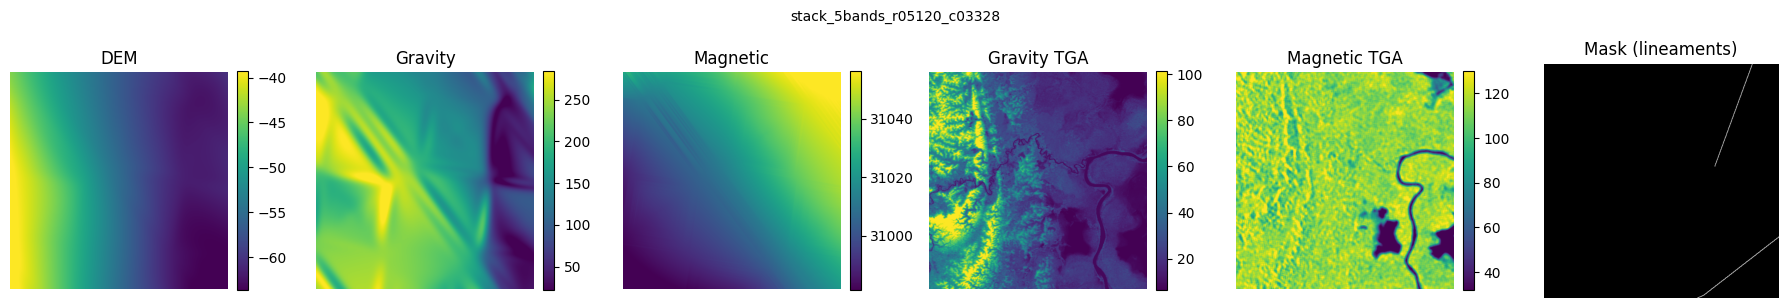

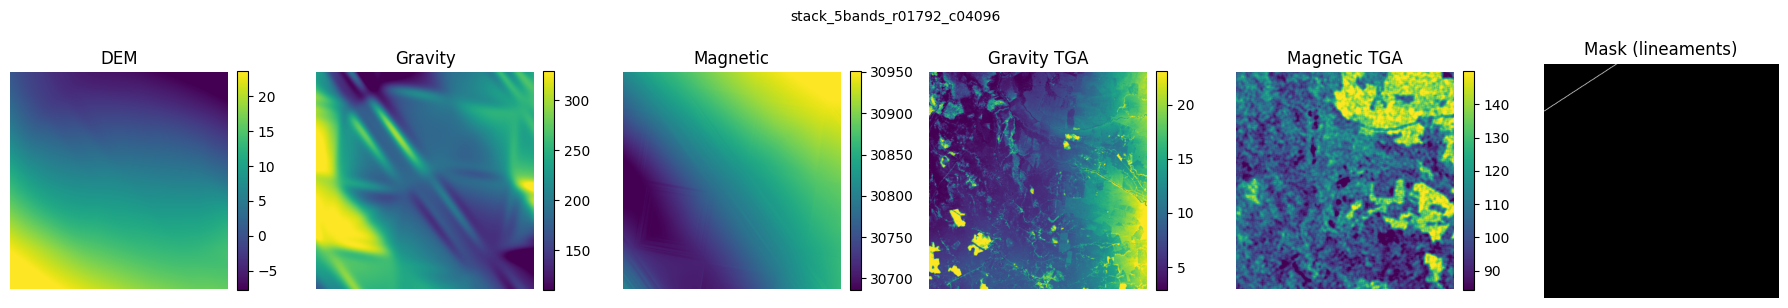

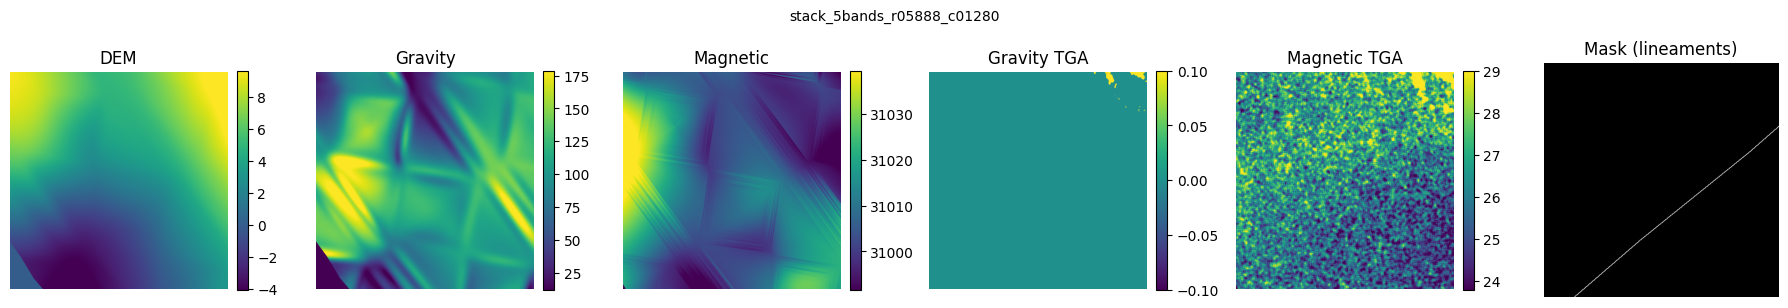

In [44]:
# Mostrar 3 tiles aleatorios
rng = np.random.default_rng(42)
sample_idx = rng.choice(len(stack_files), size=min(3, len(stack_files)), replace=False)

for idx in sample_idx:
    show_tile(stack_files[idx], mask_files[idx], BAND_NAMES)

### Fracción positiva en el dataset

`report.json` guarda metadatos de cada tile, incluida la fracción de píxeles con lineamento.

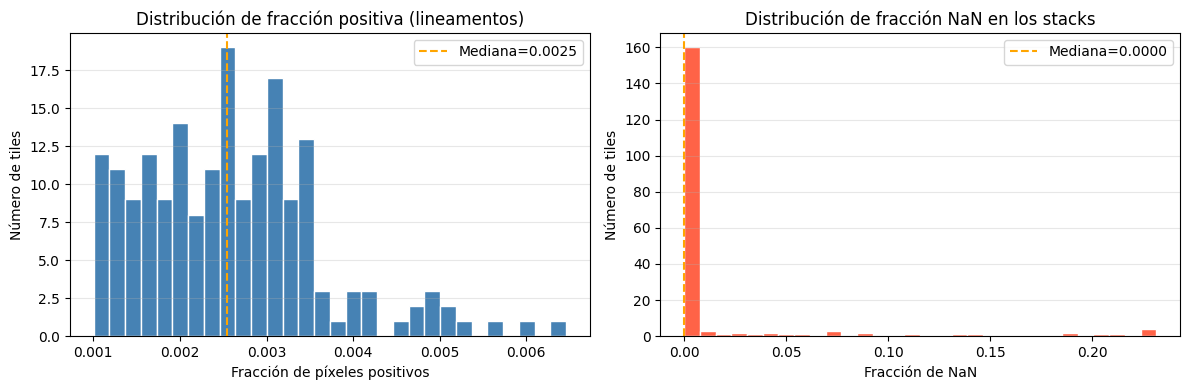

Total tiles: 187
Tile size: 512  Stride: 256
Tiles con >0 lineamentos: 187


In [45]:
with open(REPORT) as f:
    report = json.load(f)

pos_fracs = [s['positive_fraction'] for s in report['samples']]
nan_fracs = [s['nan_fraction']      for s in report['samples']]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(pos_fracs, bins=30, color='steelblue', edgecolor='white')
axes[0].set_title('Distribución de fracción positiva (lineamentos)')
axes[0].set_xlabel('Fracción de píxeles positivos')
axes[0].set_ylabel('Número de tiles')
axes[0].axvline(np.median(pos_fracs), color='orange', linestyle='--', label=f'Mediana={np.median(pos_fracs):.4f}')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

axes[1].hist(nan_fracs, bins=30, color='tomato', edgecolor='white')
axes[1].set_title('Distribución de fracción NaN en los stacks')
axes[1].set_xlabel('Fracción de NaN')
axes[1].set_ylabel('Número de tiles')
axes[1].axvline(np.median(nan_fracs), color='orange', linestyle='--', label=f'Mediana={np.median(nan_fracs):.4f}')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Total tiles: {report['num_samples']}")
print(f"Tile size: {report['tile_size']}  Stride: {report['stride']}")
print(f"Tiles con >0 lineamentos: {sum(p>0 for p in pos_fracs)}")

## 2. Tiles multifuente – `tmp_multisource_test` (26 canales)

Se agrupan los 26 canales por fuente (DEM, gravity, magnetic) y se muestran en panels.

In [46]:
MS_DIR   = os.path.join(ROOT, 'tmp_multisource_test')
CH_FILE  = os.path.join(MS_DIR, 'channels.json')

with open(CH_FILE) as f:
    channels = json.load(f)
print('Canales (26):', channels)

ms_stacks = sorted(glob.glob(os.path.join(MS_DIR, 'out_stacks_full', '*.npy')))
ms_masks  = sorted(glob.glob(os.path.join(MS_DIR, 'out_masks_full',  '*.npy')))
print(f'stacks: {len(ms_stacks)}, masks: {len(ms_masks)}')

Canales (26): ['dem', 'dem_grad_x', 'dem_grad_y', 'dem_slope_rad', 'dem_slope_deg', 'dem_curvature', 'gravity', 'gravity_regional', 'gravity_residual', 'gravity_tga', 'gravity_tilt', 'magnetic', 'magnetic_regional', 'magnetic_residual', 'magnetic_tga', 'magnetic_tilt', 'dem_x1', 'dem_x2', 'gravity_residual_x1', 'gravity_residual_x2', 'magnetic_residual_x1', 'magnetic_residual_x2', 'gravity_tilt_x1', 'gravity_tilt_x2', 'magnetic_tilt_x1', 'magnetic_tilt_x2']
stacks: 2, masks: 2


In [47]:
def show_multisource_tile(stack_path, mask_path, channel_names, n_cols=6):
    """Muestra todos los canales de un tile multifuente en una cuadrícula."""
    stack = np.load(stack_path)  # (H, W, C) o (C, H, W)
    if stack.ndim == 3 and stack.shape[0] == len(channel_names):
        stack = np.transpose(stack, (1, 2, 0))  # → (H, W, C)
    mask = np.load(mask_path)

    n_ch = stack.shape[2]
    total_panels = n_ch + 1
    n_rows = int(np.ceil(total_panels / n_cols))

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 2.5, n_rows * 2.5))
    axes_flat = axes.flatten()

    for i in range(n_ch):
        band = stack[:, :, i]
        vmin, vmax = np.nanpercentile(band, 2), np.nanpercentile(band, 98)
        axes_flat[i].imshow(band, cmap='RdBu_r', vmin=vmin, vmax=vmax)
        axes_flat[i].set_title(channel_names[i], fontsize=7)
        axes_flat[i].axis('off')

    axes_flat[n_ch].imshow(mask, cmap='gray', vmin=0, vmax=1)
    axes_flat[n_ch].set_title('Mask', fontsize=7)
    axes_flat[n_ch].axis('off')

    for ax in axes_flat[total_panels:]:
        ax.axis('off')

    tile_name = os.path.basename(stack_path).replace('.npy', '')
    fig.suptitle(f'Multisource stack – {tile_name}', y=1.01, fontsize=11)
    fig.tight_layout()
    plt.show()

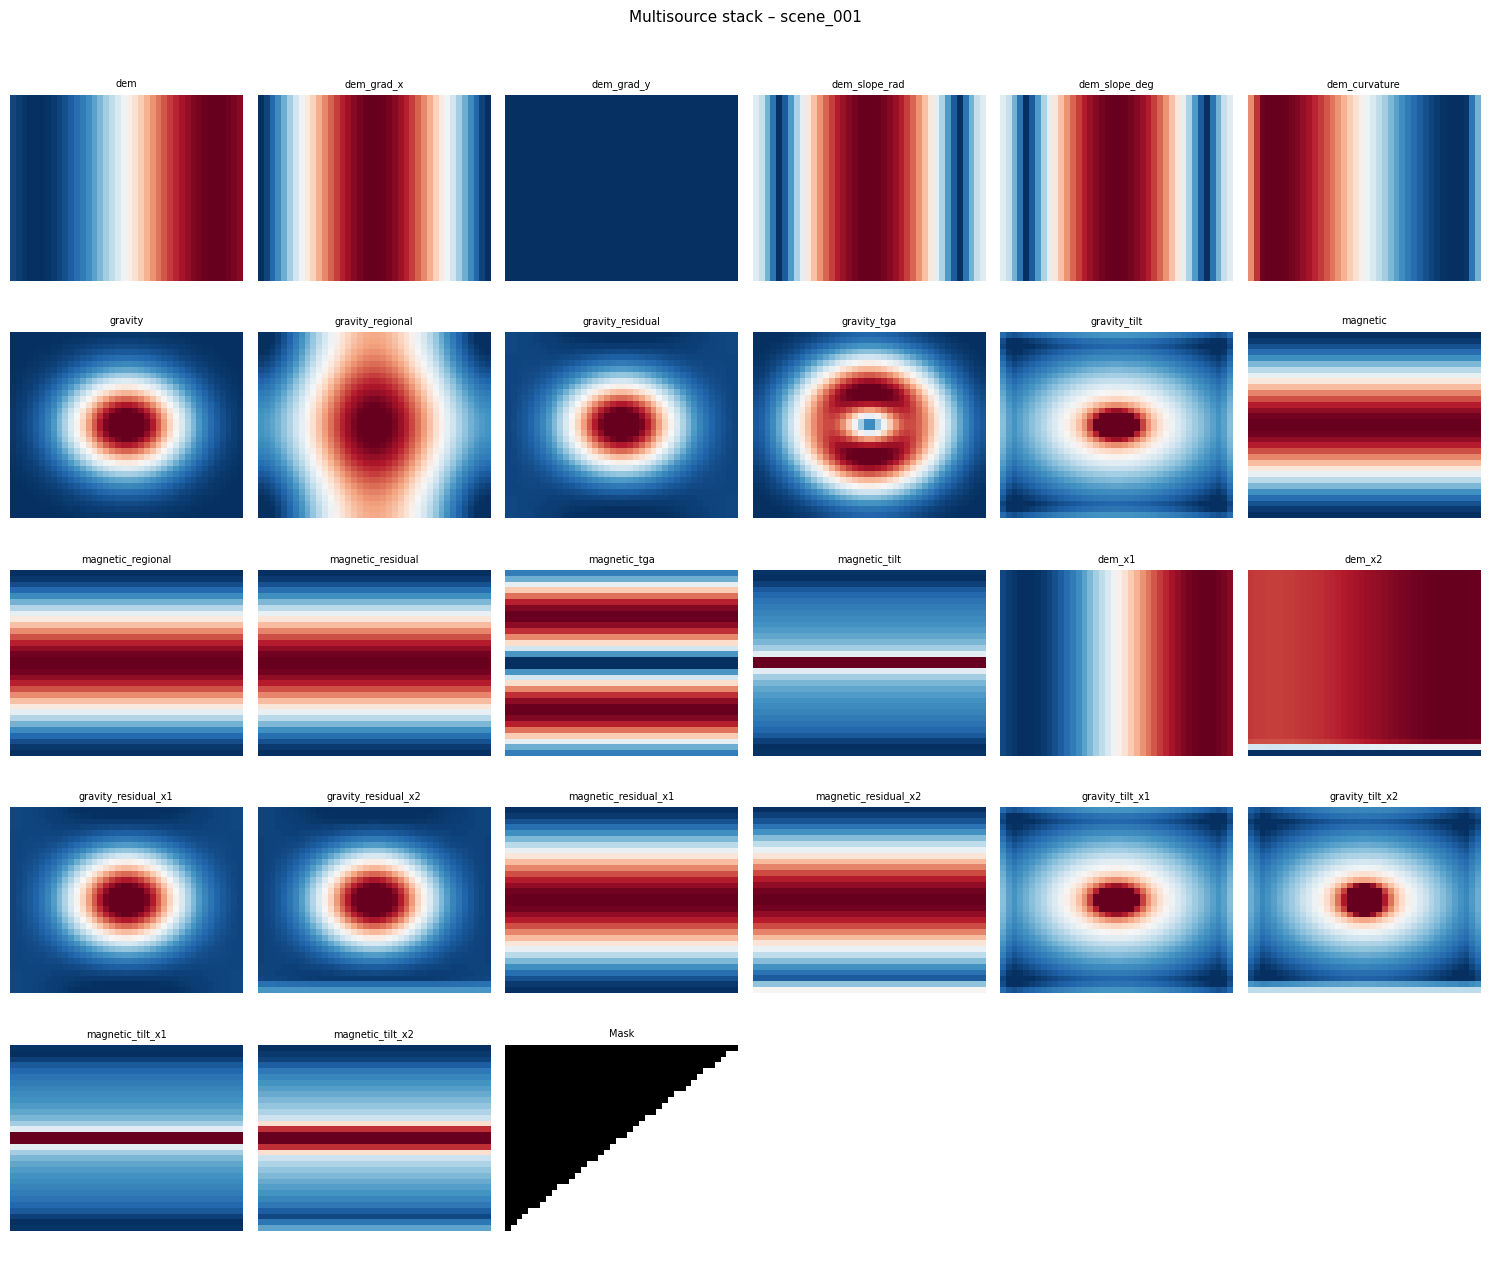

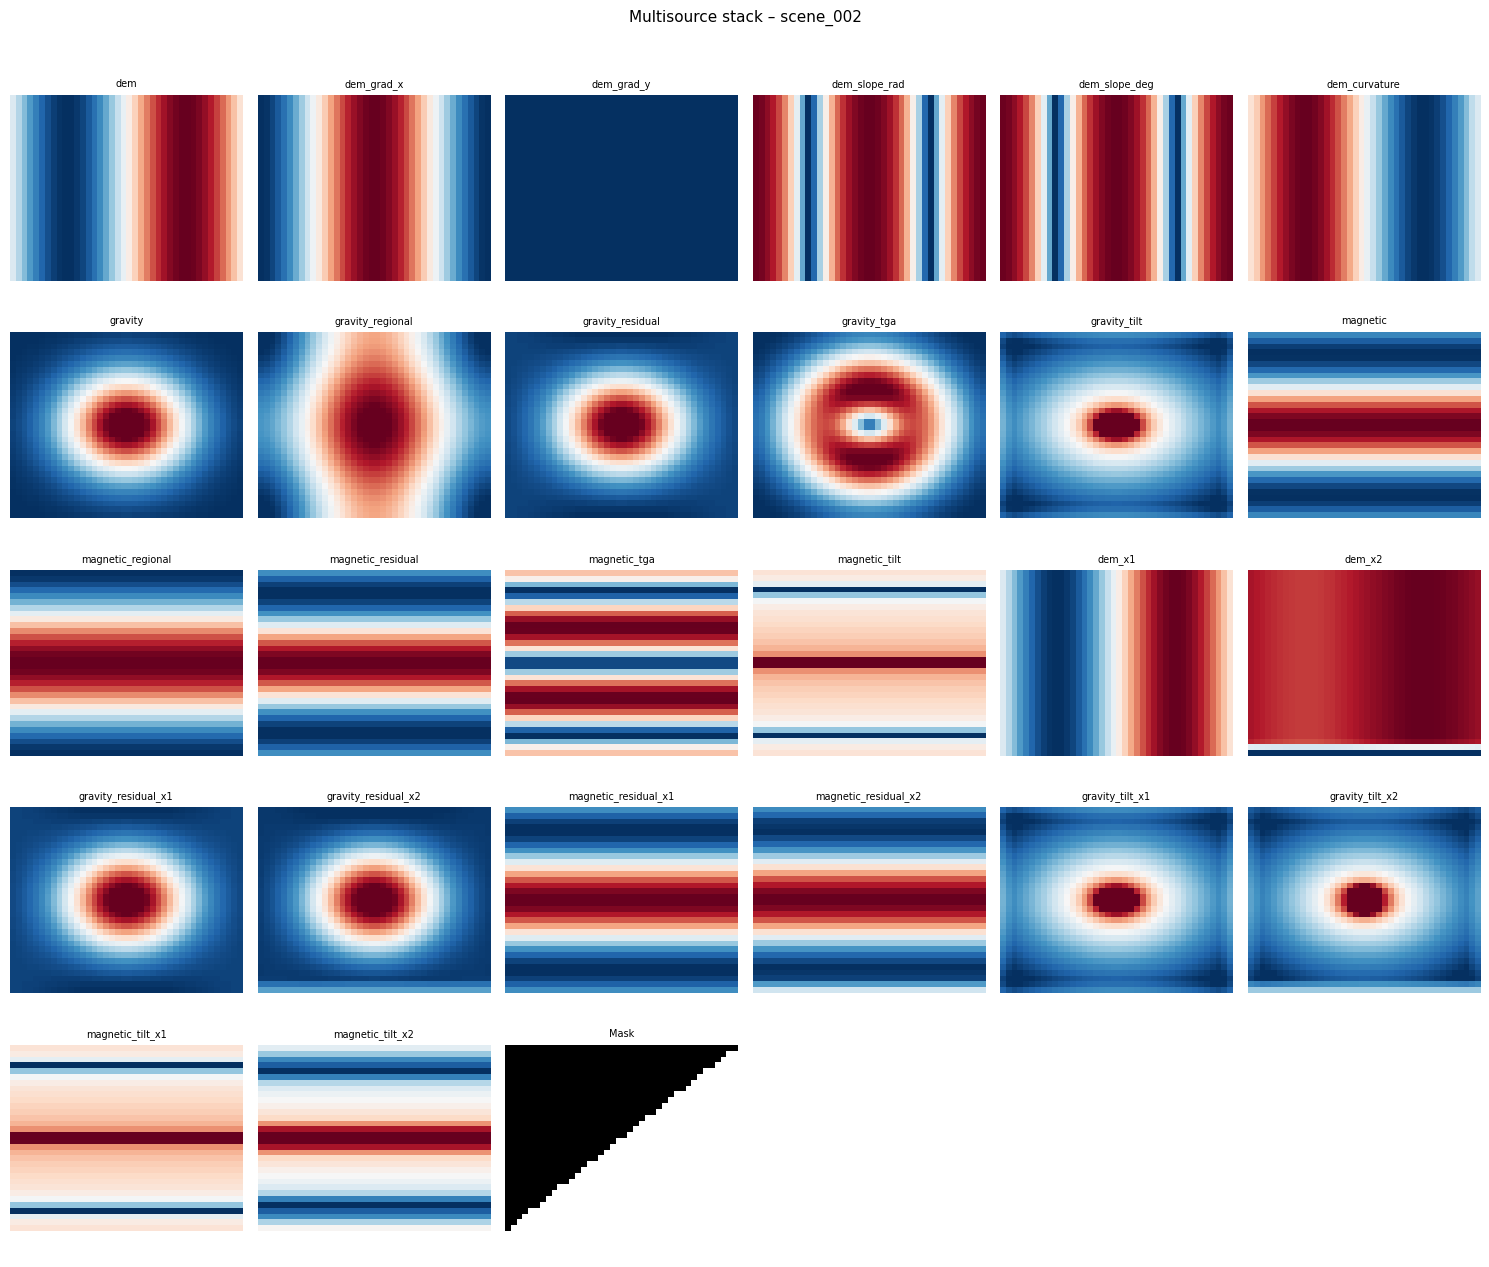

In [48]:
for sp, mp in zip(ms_stacks, ms_masks):
    show_multisource_tile(sp, mp, channels)

## 3. Mapas de incertidumbre – MC-Dropout

El pipeline de inferencia exporta por escena cuatro mapas:

| Archivo | Significado |
|---|---|
| `*_mean.tif` | Predicción media (probabilidad de lineamento) |
| `*_std.tif` | Desviación estándar (incertidumbre aleatórica) |
| `*_entropy.tif` | Entropía predictiva (incertidumbre total) |
| `*_mutual_information.tif` | Información mutua (incertidumbre epistémica) |
| `*_mask.tif` | Máscara umbralada (predicción binaria) |

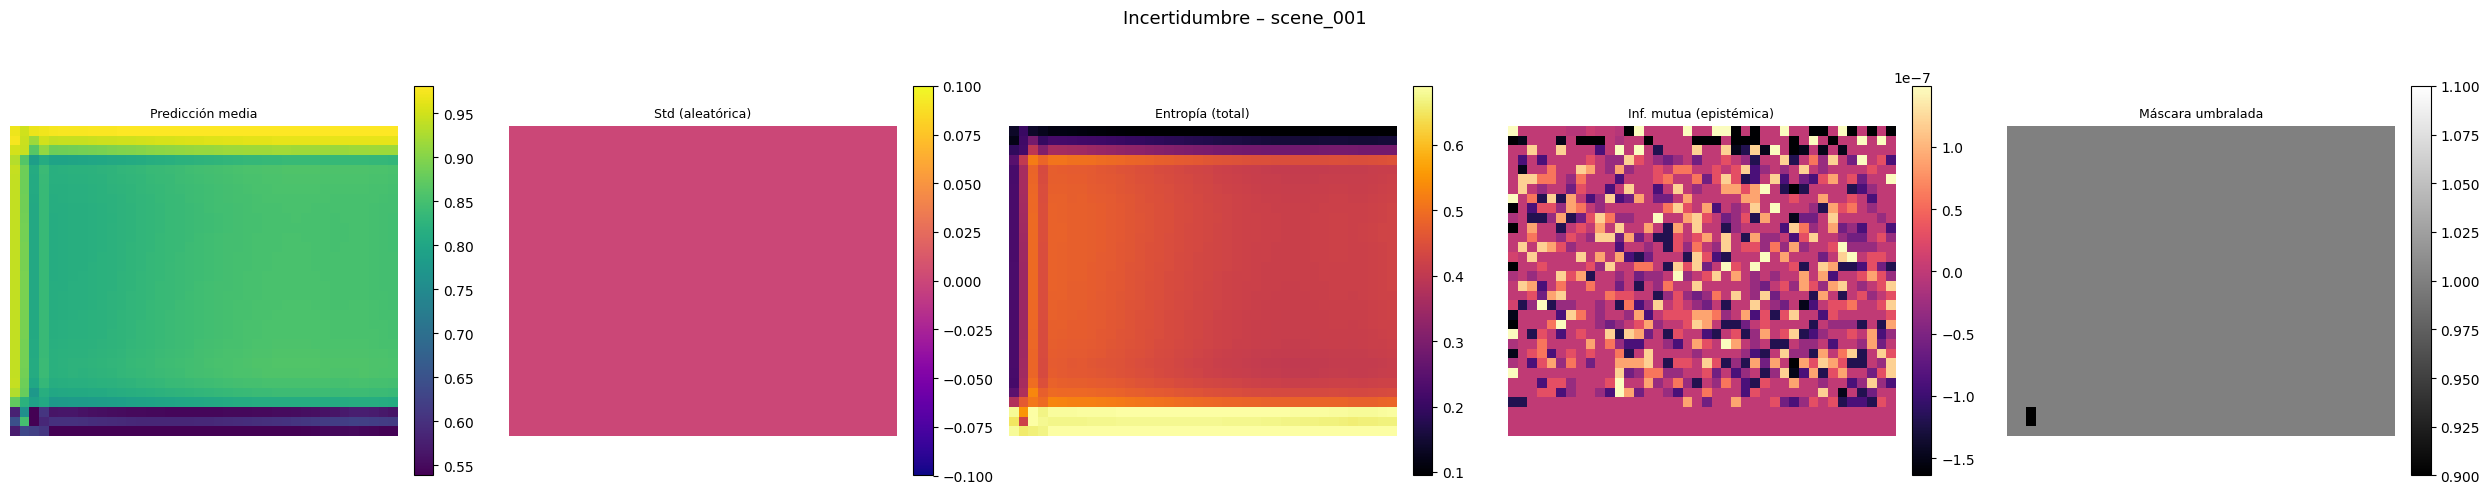

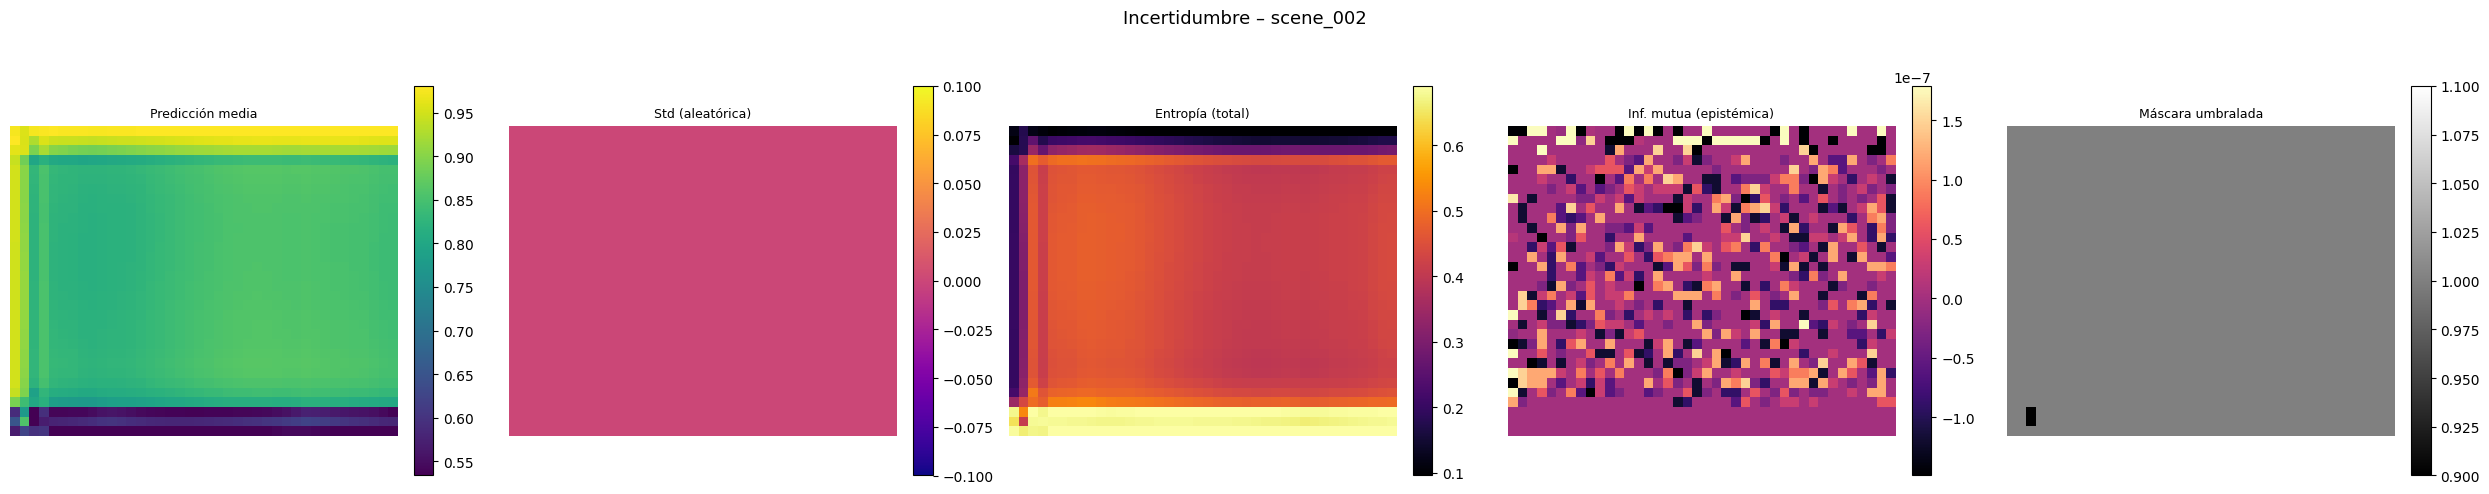

In [49]:
UNCERT_DIR = os.path.join(MS_DIR, 'uncertainty_full')

METRICS = ['mean', 'std', 'entropy', 'mutual_information', 'mask']
METRIC_LABELS = ['Predicción media', 'Std (aleatórica)', 'Entropía (total)', 'Inf. mutua (epistémica)', 'Máscara umbralada']
METRIC_CMAPS  = ['viridis', 'plasma', 'inferno', 'magma', 'gray']

scenes = ['scene_001', 'scene_002']


def load_tif_band(path):
    """Lee la primera banda de un GeoTIFF como numpy array 2-D."""
    arr = np.array(Image.open(path)).astype(np.float32)
    return arr


for scene in scenes:
    files = [os.path.join(UNCERT_DIR, f'{scene}_{m}.tif') for m in METRICS]
    if not all(os.path.exists(p) for p in files):
        print(f'Falta algún archivo de {scene}, omitiendo.')
        continue

    arrays = [load_tif_band(p) for p in files]

    fig, axes = plt.subplots(1, len(METRICS), figsize=(5 * len(METRICS), 5))
    for ax, arr, label, cmap in zip(axes, arrays, METRIC_LABELS, METRIC_CMAPS):
        vmin = np.nanpercentile(arr, 2)
        vmax = np.nanpercentile(arr, 98)
        im = ax.imshow(arr, cmap=cmap, vmin=vmin, vmax=vmax)
        ax.set_title(label, fontsize=9)
        ax.axis('off')
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    fig.suptitle(f'Incertidumbre – {scene}', fontsize=13, y=1.01)
    fig.tight_layout()
    plt.show()

## 4. Comparación: input stack vs predicción vs máscara GT

Se selecciona el primer canal de cada stack multifuente y se compara con la predicción media y la máscara de referencia.

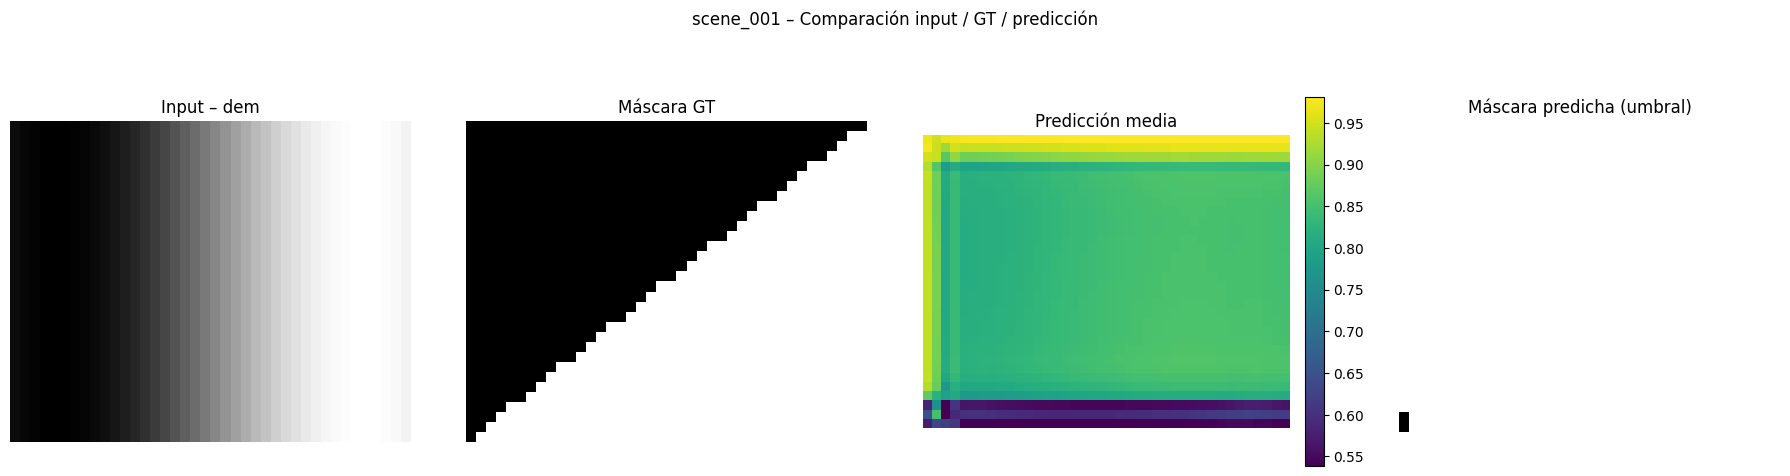

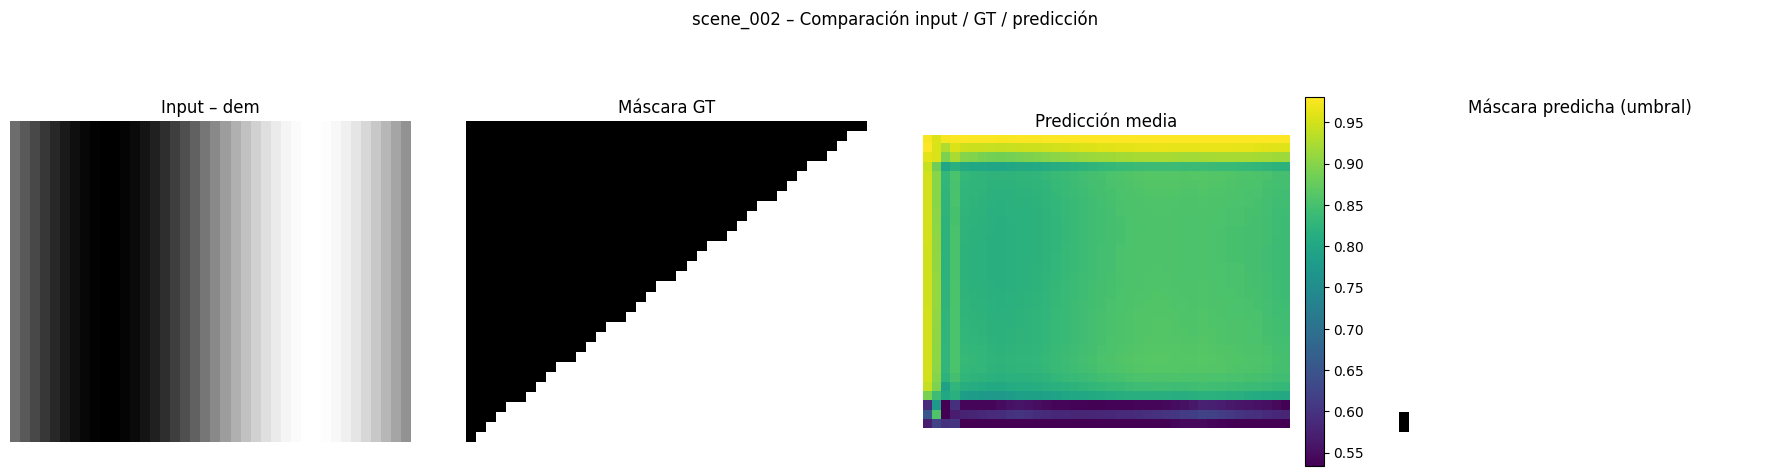

In [50]:
for i, (sp, mp, scene) in enumerate(zip(ms_stacks, ms_masks, scenes)):
    stack = np.load(sp)
    if stack.ndim == 3 and stack.shape[0] == len(channels):
        stack = np.transpose(stack, (1, 2, 0))
    mask = np.load(mp)

    mean_path = os.path.join(UNCERT_DIR, f'{scene}_mean.tif')
    pred_mask_path = os.path.join(UNCERT_DIR, f'{scene}_mask.tif')
    if not os.path.exists(mean_path):
        continue

    mean_arr = load_tif_band(mean_path)
    pred_mask_arr = load_tif_band(pred_mask_path)

    # primer canal del stack como representación del input
    inp = stack[:, :, 0]

    fig, axes = plt.subplots(1, 4, figsize=(18, 5))

    vmin, vmax = np.nanpercentile(inp, 2), np.nanpercentile(inp, 98)
    axes[0].imshow(inp, cmap='gray', vmin=vmin, vmax=vmax)
    axes[0].set_title(f'Input – {channels[0]}')
    axes[0].axis('off')

    axes[1].imshow(mask, cmap='gray', vmin=0, vmax=1)
    axes[1].set_title('Máscara GT')
    axes[1].axis('off')

    im2 = axes[2].imshow(mean_arr, cmap='viridis',
                          vmin=np.nanpercentile(mean_arr, 2),
                          vmax=np.nanpercentile(mean_arr, 98))
    axes[2].set_title('Predicción media')
    axes[2].axis('off')
    plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

    axes[3].imshow(pred_mask_arr, cmap='gray', vmin=0, vmax=1)
    axes[3].set_title('Máscara predicha (umbral)')
    axes[3].axis('off')

    fig.suptitle(f'{scene} – Comparación input / GT / predicción', fontsize=12, y=1.01)
    fig.tight_layout()
    plt.show()

## 5. Sentinel-2 open data: California y otros AOIs

Los AOIs abiertos descargados tienen 4 bandas (`red`, `green`, `blue`, `nir`). Como los GeoTIFFs son grandes (`10980 x 10980`), esta exploración usa **previews reescaladas** para inspección rápida.

Qué puedes ver visualmente en la **entrada**:
- **RGB natural**: drenajes, litología expuesta, vegetación, zonas urbanas, nubosidad.
- **Falso color NIR-R-G**: resalta vegetación y diferencias de humedad.
- **NDVI**: ayuda a separar áreas vegetadas de roca/suelo desnudo.
- **Histogramas por banda**: muestran contraste, saturación, ceros y rango útil.
- **Scatter Red vs NIR**: revela separabilidad entre clases superficiales.

Qué estadísticas vale la pena revisar:
- min, max, percentiles 2/50/98 por banda
- fracción de ceros / nodata
- media y desviación estándar por banda
- NDVI medio, desviación y percentiles
- correlación entre bandas
- entropía o textura local si luego quieres analizar complejidad espacial

In [51]:
from pathlib import Path
from PIL import Image

Image.MAX_IMAGE_PIXELS = None

S2_ROOT = Path(ROOT) / 'data' / 'OpenData' / 'non_colombia' / 'sentinel2'
NOTES_FILE = Path(ROOT) / 'data' / 'NOTES_OPEN_DATA.md'


def group_sentinel2_scenes(base_dir):
    catalog = {}
    for aoi_dir in sorted([path for path in Path(base_dir).iterdir() if path.is_dir()]):
        scene_map = {}
        for tif_path in sorted(aoi_dir.glob('*.tif')):
            stem = tif_path.stem
            band = stem.split('_')[-1]
            scene_id = stem[: -(len(band) + 1)]
            scene_map.setdefault(scene_id, {})[band] = tif_path
        catalog[aoi_dir.name] = scene_map
    return catalog


def parse_cloud_cover(notes_path):
    rows = {}
    current_aoi = None
    current_scene = None
    with open(notes_path, encoding='utf-8') as handle:
        for raw_line in handle:
            line = raw_line.strip()
            if line.startswith('### AOI: '):
                current_aoi = line.split(': ', 1)[1]
                rows.setdefault(current_aoi, {})
            elif line.startswith('- Scene: '):
                current_scene = line.split(': ', 1)[1]
            elif line.startswith('Cloud cover:') and current_aoi and current_scene:
                value = float(line.split(':', 1)[1].strip())
                rows[current_aoi][current_scene] = value
    return rows


def load_preview(path, max_dim=1024):
    image = Image.open(path)
    width, height = image.size
    scale = min(1.0, max_dim / max(width, height))
    if scale < 1.0:
        image = image.resize((int(width * scale), int(height * scale)), Image.Resampling.BILINEAR)
    return np.array(image, dtype=np.float32)


def robust_scale(array, low=2, high=98):
    valid = array[np.isfinite(array)]
    if valid.size == 0:
        return np.zeros_like(array, dtype=np.float32)
    lo, hi = np.percentile(valid, [low, high])
    if hi <= lo:
        return np.zeros_like(array, dtype=np.float32)
    return np.clip((array - lo) / (hi - lo), 0, 1)


def compute_band_stats(array):
    valid = array[np.isfinite(array)]
    return {
        'min': float(np.min(valid)),
        'p02': float(np.percentile(valid, 2)),
        'p50': float(np.percentile(valid, 50)),
        'p98': float(np.percentile(valid, 98)),
        'max': float(np.max(valid)),
        'mean': float(np.mean(valid)),
        'std': float(np.std(valid)),
        'zero_frac': float(np.mean(valid == 0)),
    }


def show_sentinel2_scene(aoi_name, scene_id, band_paths, cloud_cover=None, max_dim=1024):
    red = load_preview(band_paths['red'], max_dim=max_dim)
    green = load_preview(band_paths['green'], max_dim=max_dim)
    blue = load_preview(band_paths['blue'], max_dim=max_dim)
    nir = load_preview(band_paths['nir'], max_dim=max_dim)

    rgb = np.dstack([robust_scale(red), robust_scale(green), robust_scale(blue)])
    false_color = np.dstack([robust_scale(nir), robust_scale(red), robust_scale(green)])
    ndvi = (nir - red) / (nir + red + 1e-6)

    stats = {
        'red': compute_band_stats(red),
        'green': compute_band_stats(green),
        'blue': compute_band_stats(blue),
        'nir': compute_band_stats(nir),
        'ndvi_mean': float(np.mean(ndvi)),
        'ndvi_std': float(np.std(ndvi)),
        'ndvi_p02': float(np.percentile(ndvi, 2)),
        'ndvi_p98': float(np.percentile(ndvi, 98)),
    }

    fig, axes = plt.subplots(2, 3, figsize=(16, 10))

    axes[0, 0].imshow(rgb)
    axes[0, 0].set_title('RGB natural')
    axes[0, 0].axis('off')

    axes[0, 1].imshow(false_color)
    axes[0, 1].set_title('Falso color (NIR-R-G)')
    axes[0, 1].axis('off')

    ndvi_im = axes[0, 2].imshow(ndvi, cmap='RdYlGn', vmin=-1, vmax=1)
    axes[0, 2].set_title('NDVI')
    axes[0, 2].axis('off')
    plt.colorbar(ndvi_im, ax=axes[0, 2], fraction=0.046, pad=0.04)

    axes[1, 0].hist(red.ravel(), bins=80, alpha=0.5, label='Red', color='red')
    axes[1, 0].hist(green.ravel(), bins=80, alpha=0.5, label='Green', color='green')
    axes[1, 0].hist(blue.ravel(), bins=80, alpha=0.5, label='Blue', color='blue')
    axes[1, 0].hist(nir.ravel(), bins=80, alpha=0.5, label='NIR', color='black')
    axes[1, 0].set_title('Histogramas por banda')
    axes[1, 0].legend()
    axes[1, 0].grid(alpha=0.3)

    sample_step = max(1, int(np.sqrt(red.size / 6000)))
    axes[1, 1].scatter(red[::sample_step, ::sample_step].ravel(), nir[::sample_step, ::sample_step].ravel(), s=4, alpha=0.15)
    axes[1, 1].set_title('Scatter Red vs NIR')
    axes[1, 1].set_xlabel('Red')
    axes[1, 1].set_ylabel('NIR')
    axes[1, 1].grid(alpha=0.3)

    stats_lines = [
        f"Cloud cover: {cloud_cover:.3f}" if cloud_cover is not None else 'Cloud cover: n/d',
        f"NDVI mean/std: {stats['ndvi_mean']:.3f} / {stats['ndvi_std']:.3f}",
        f"NDVI p02/p98: {stats['ndvi_p02']:.3f} / {stats['ndvi_p98']:.3f}",
        '',
    ]
    for band_name in ['red', 'green', 'blue', 'nir']:
        band_stats = stats[band_name]
        stats_lines.append(
            f"{band_name:<5} mean={band_stats['mean']:.1f} std={band_stats['std']:.1f} p02={band_stats['p02']:.1f} p98={band_stats['p98']:.1f} zero={band_stats['zero_frac']:.3f}"
        )
    axes[1, 2].axis('off')
    axes[1, 2].text(0, 1, '\n'.join(stats_lines), va='top', family='monospace', fontsize=10)

    title = f'{aoi_name} | {scene_id}'
    fig.suptitle(title, fontsize=14, y=1.02)
    fig.tight_layout()
    plt.show()

    return stats

In [52]:
s2_catalog = group_sentinel2_scenes(S2_ROOT)
cloud_catalog = parse_cloud_cover(NOTES_FILE)

print('AOIs disponibles:')
for aoi_name, scenes_dict in s2_catalog.items():
    print(f'- {aoi_name}: {len(scenes_dict)} escenas')
    for scene_id in scenes_dict:
        cloud = cloud_catalog.get(aoi_name, {}).get(scene_id)
        cloud_text = f'{cloud:.3f}' if cloud is not None else 'n/d'
        print(f'    {scene_id} | cloud_cover={cloud_text}')

AOIs disponibles:
- california_san_andreas: 3 escenas
    S2A_10SEG_20240324_0_L2A | cloud_cover=n/d
    S2B_10SEG_20241127_0_L2A | cloud_cover=0.035
    S2B_10SEH_20241204_0_L2A | cloud_cover=0.001
- iceland_thingvellir_rift: 2 escenas
    S2B_27VVL_20241116_0_L2A | cloud_cover=1.443
    S2B_27WWM_20241122_0_L2A | cloud_cover=1.105
- turkiye_north_anatolian: 2 escenas
    S2B_36TTK_20241231_0_L2A | cloud_cover=0.600
    S2B_36TUL_20241231_0_L2A | cloud_cover=0.407


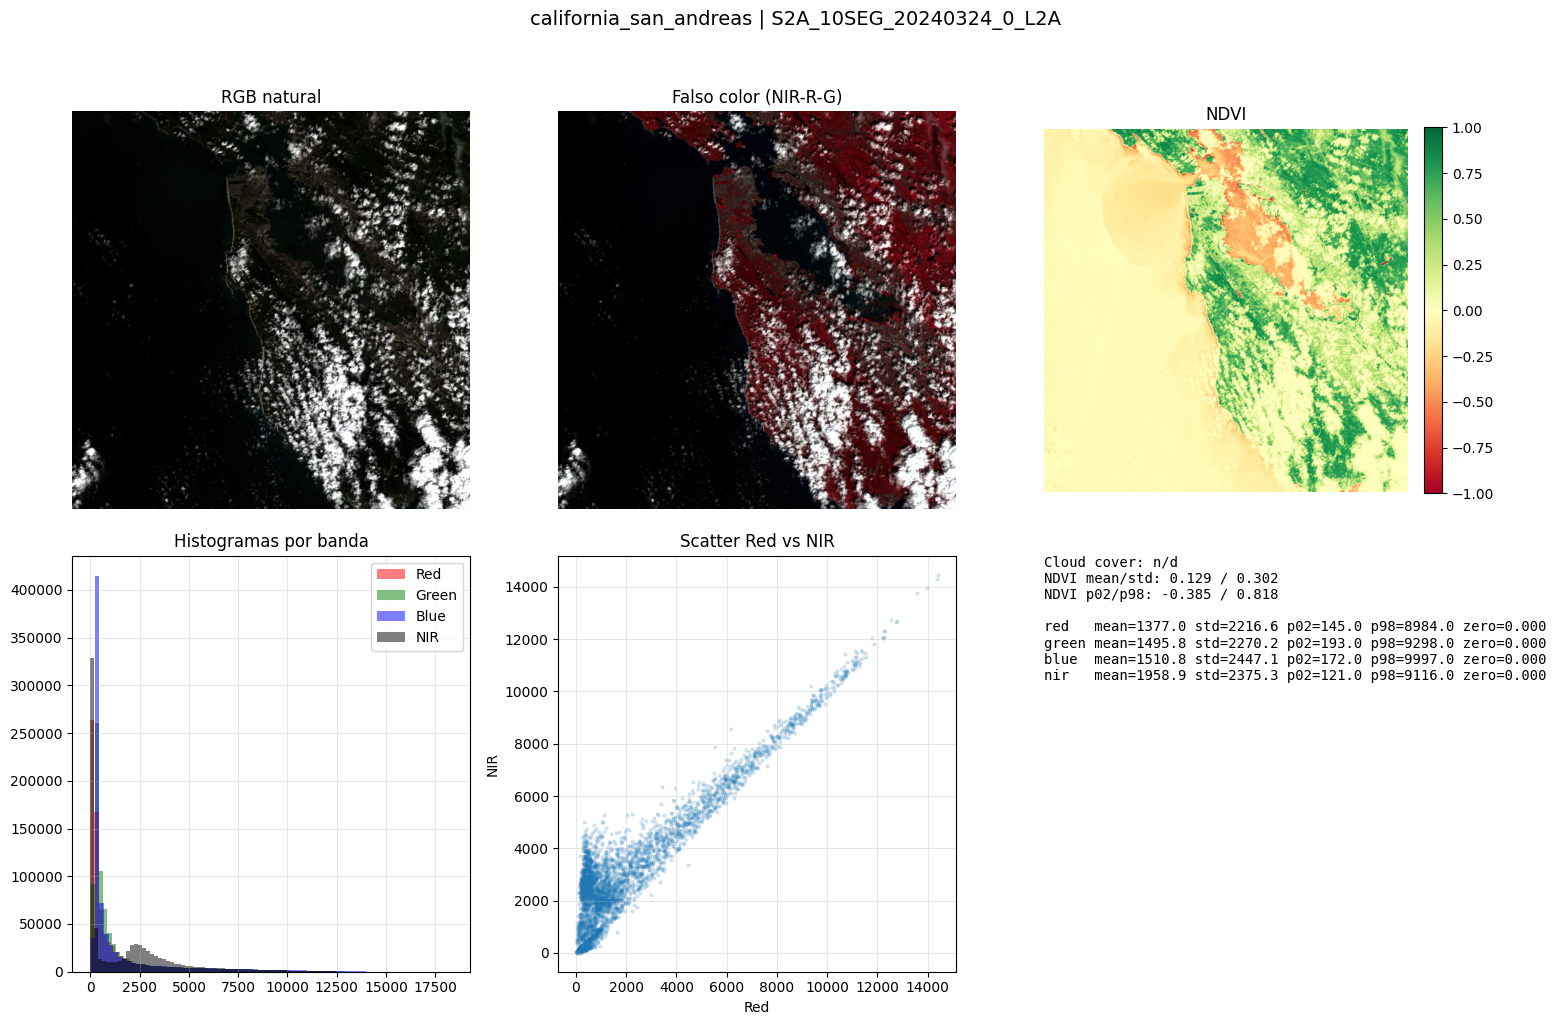

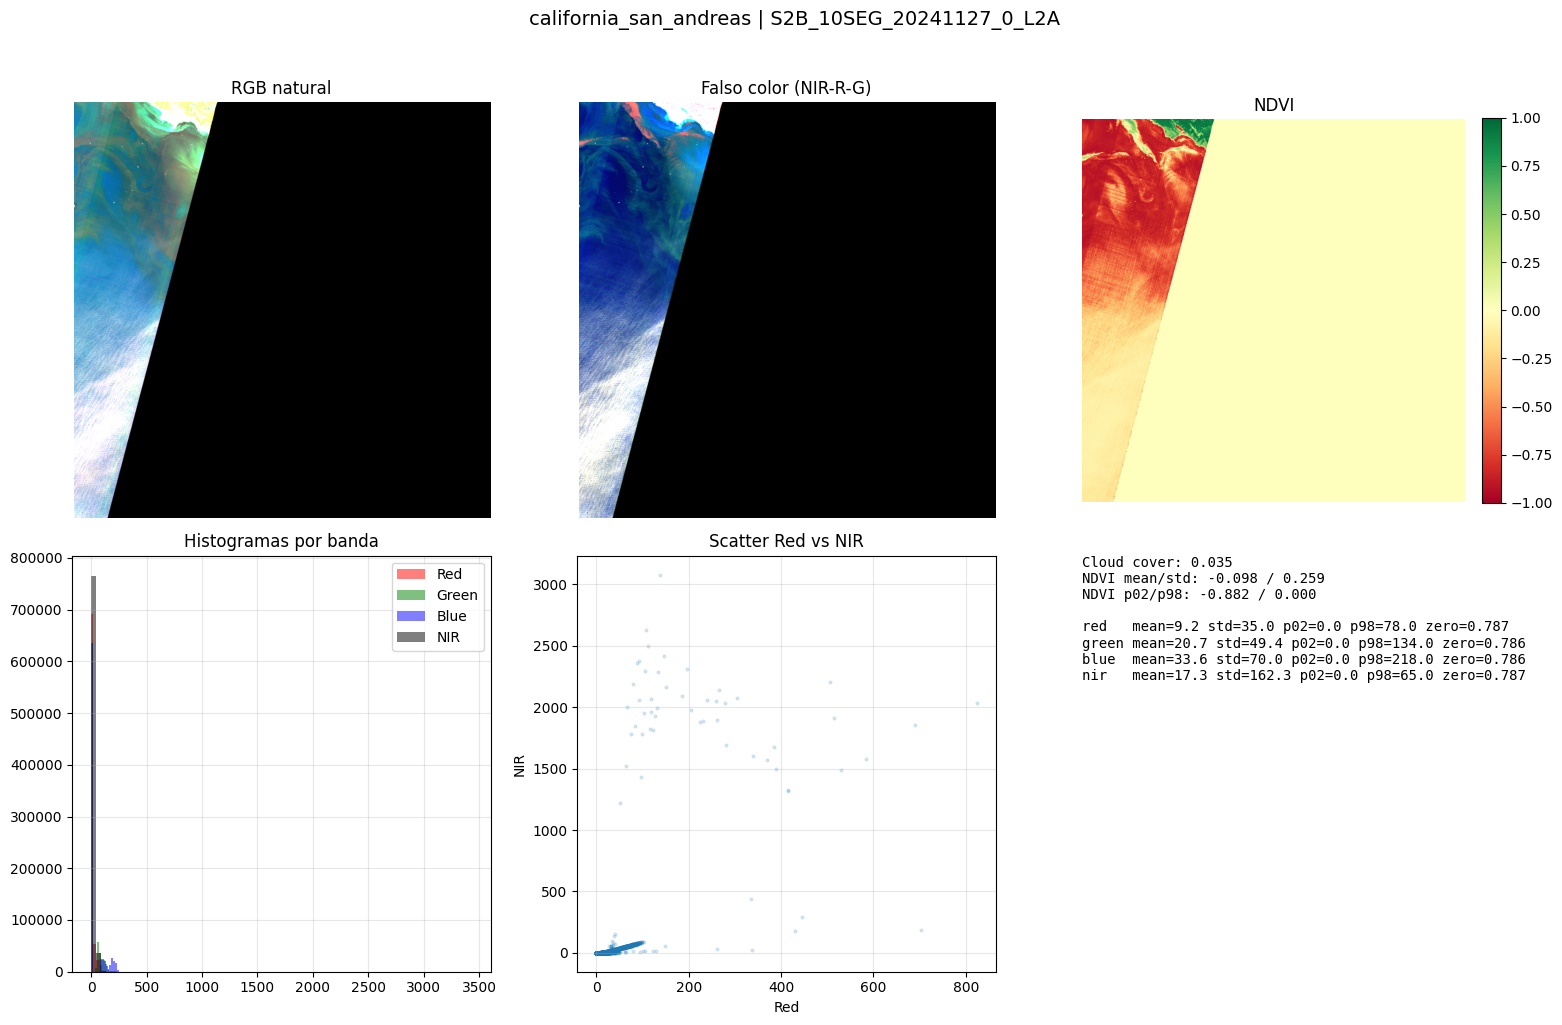

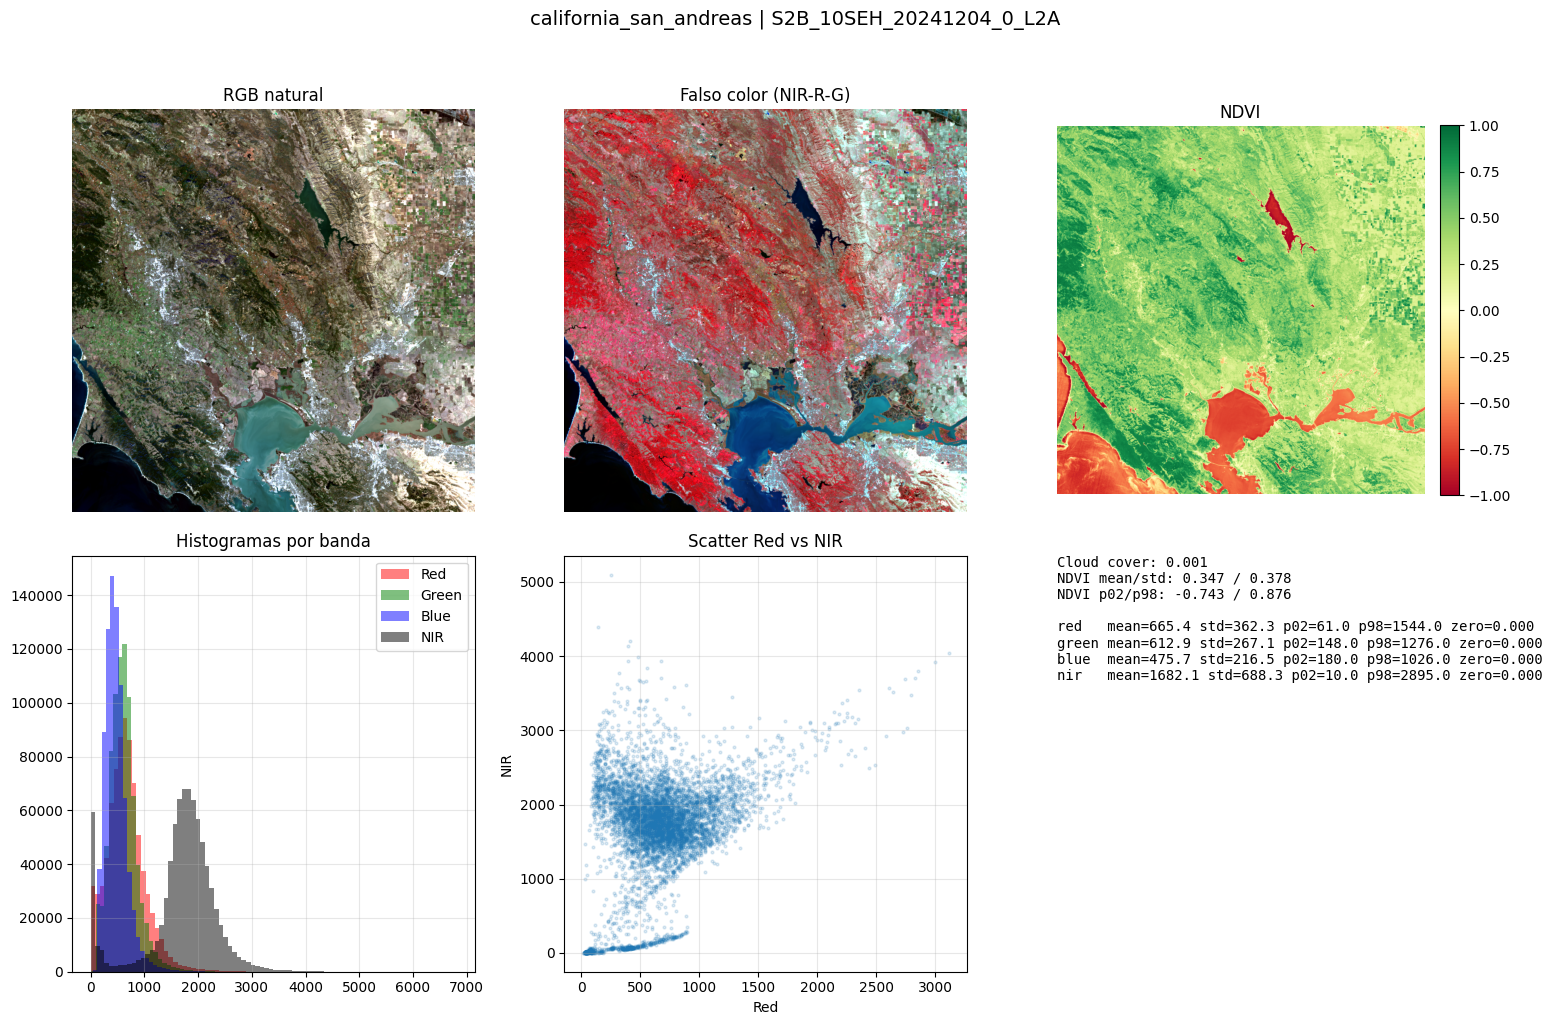

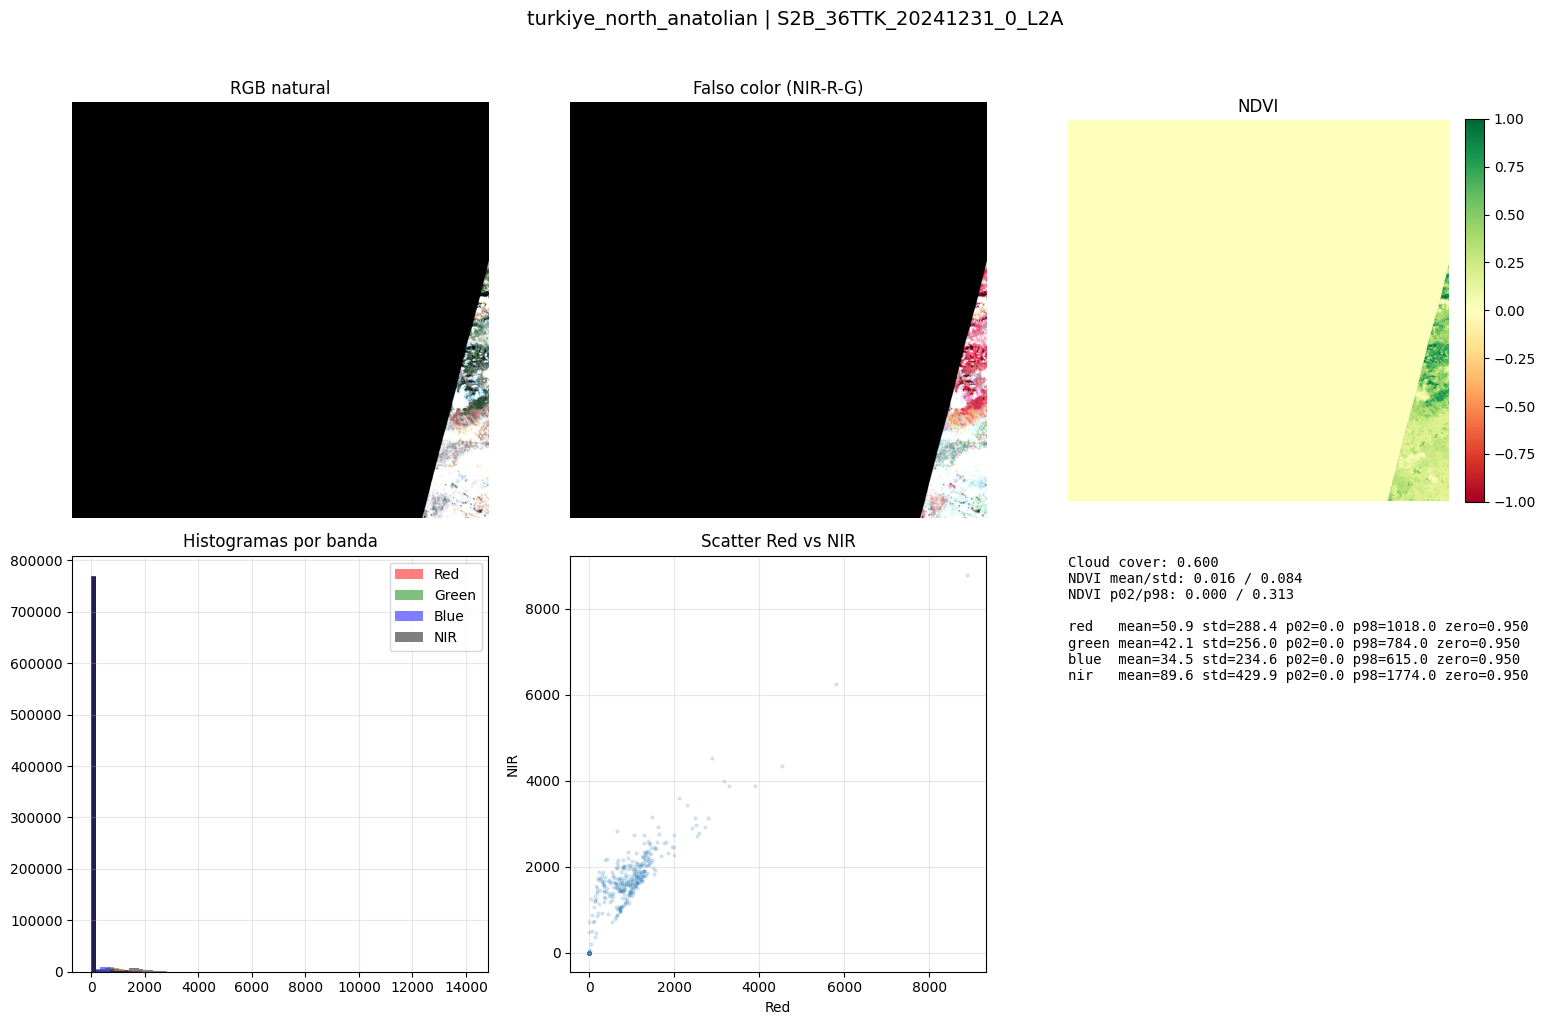

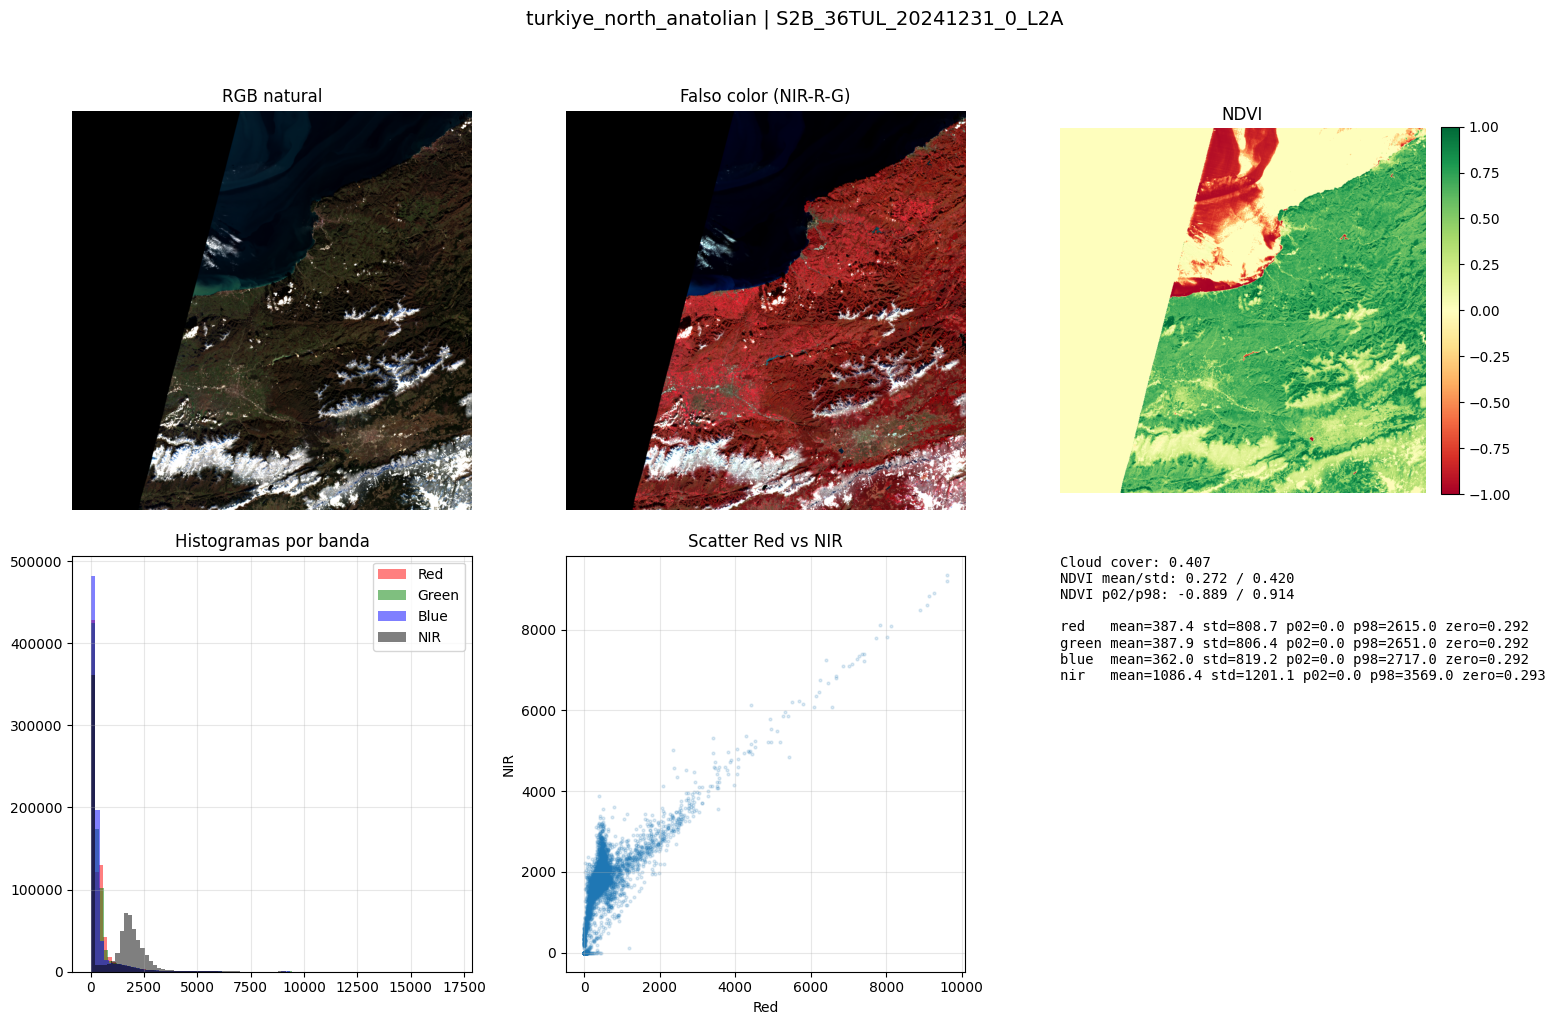

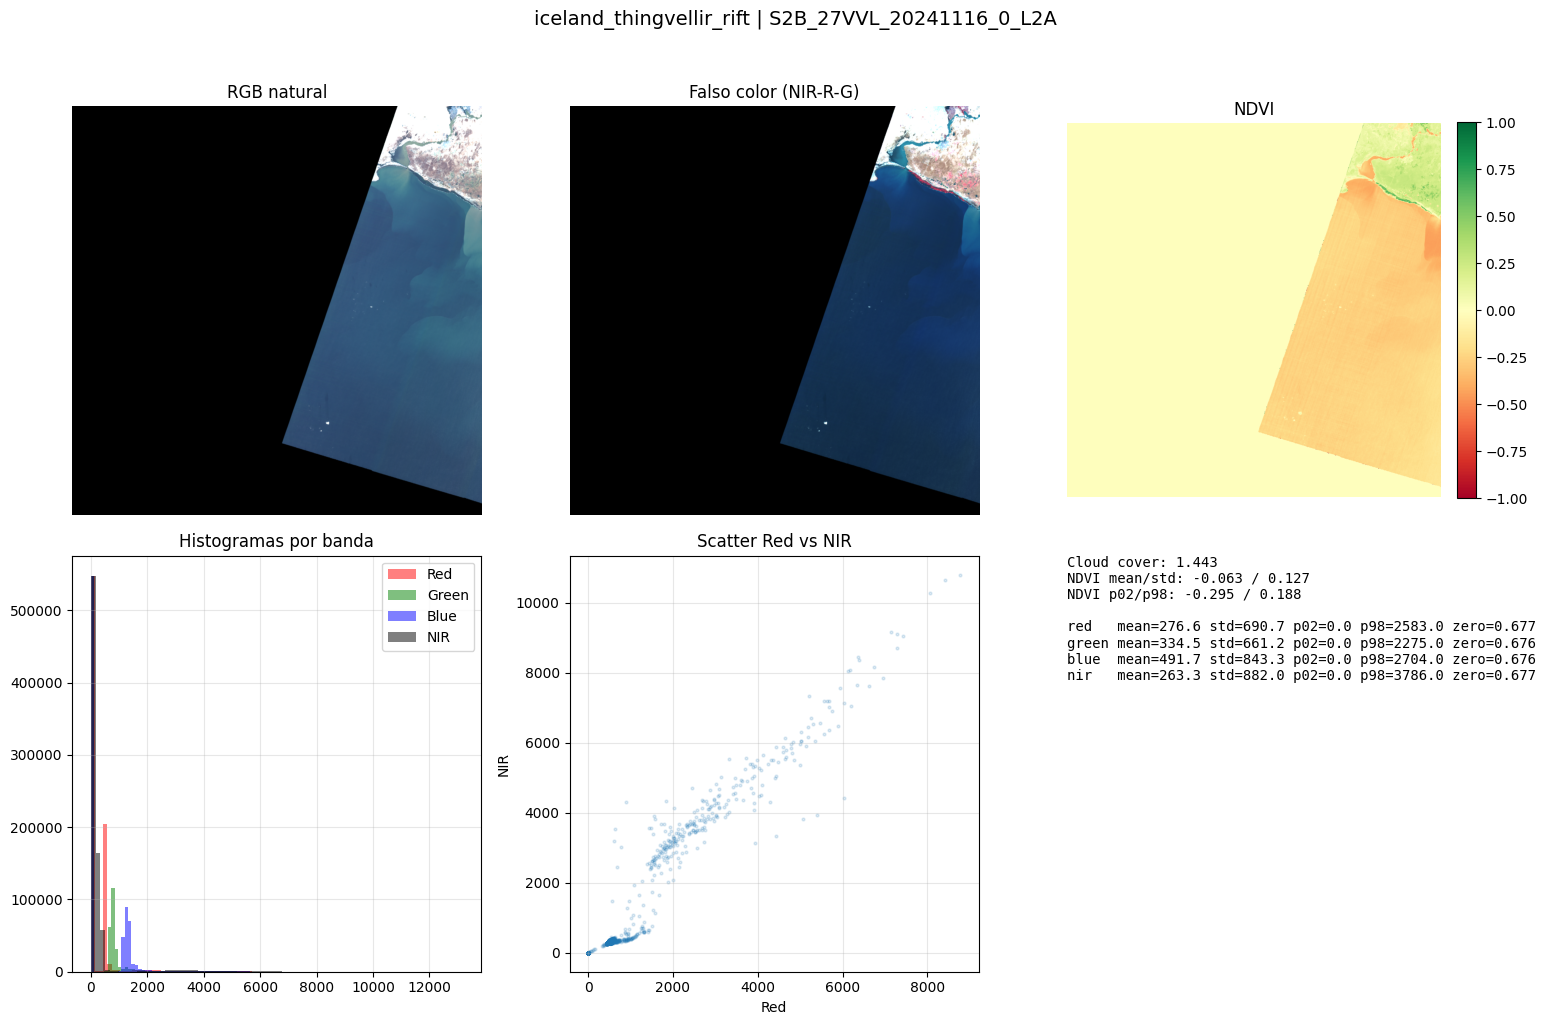

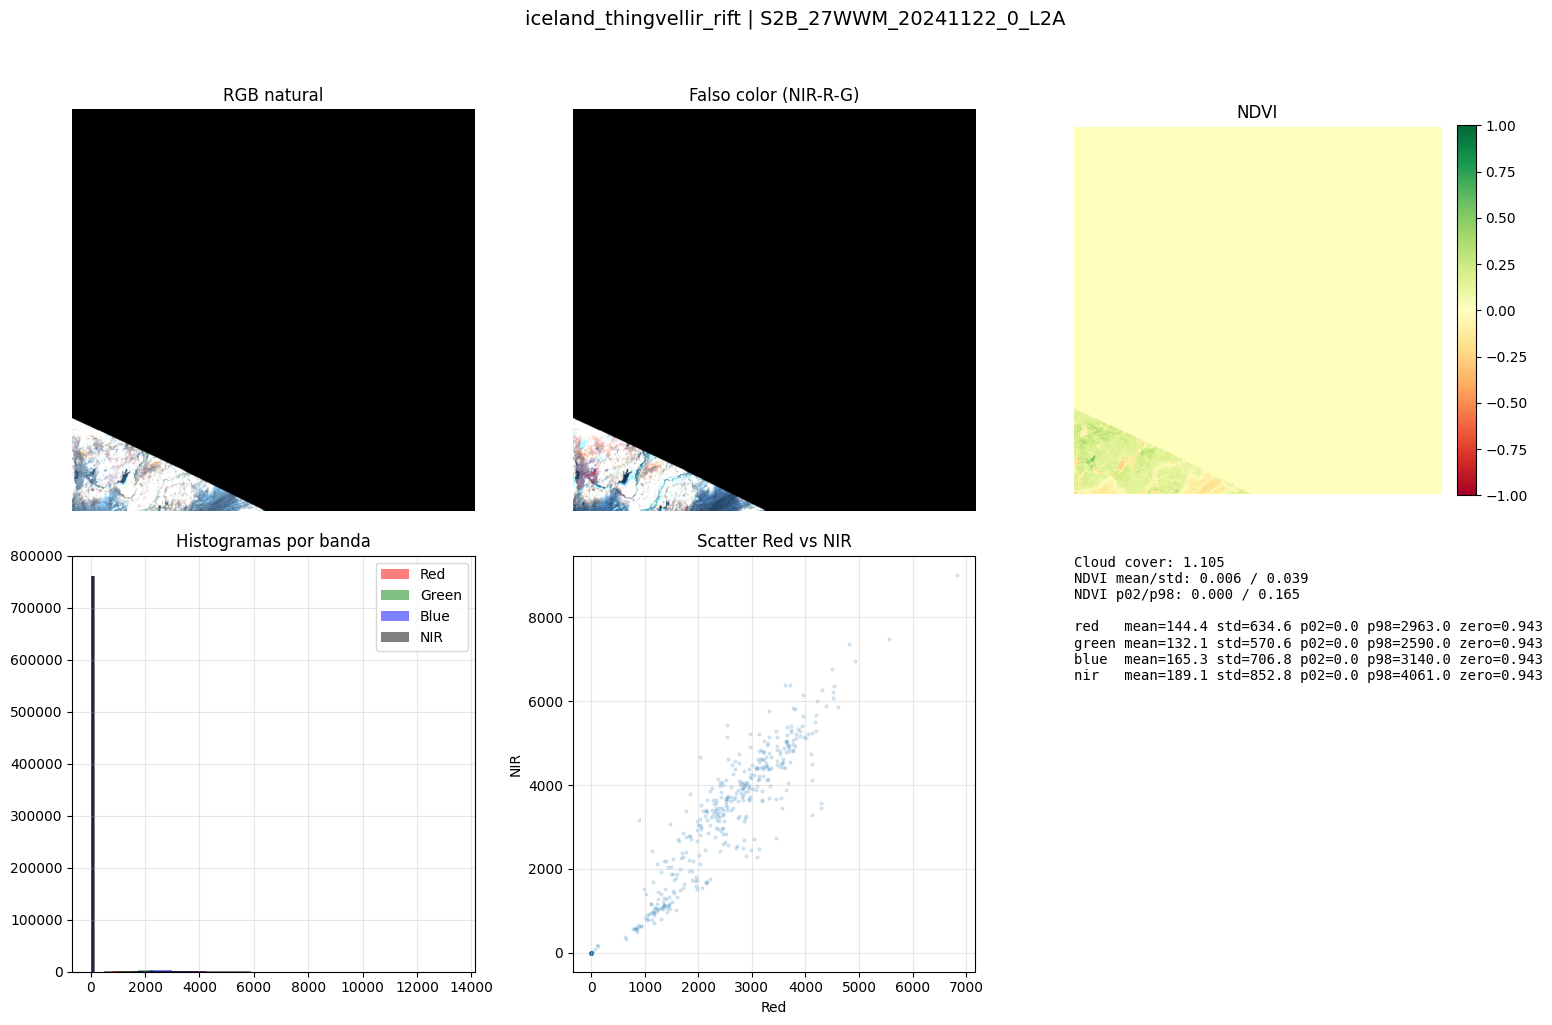

In [53]:
preferred_order = [
    'california_san_andreas',
    'turkiye_north_anatolian',
    'iceland_thingvellir_rift',
]

for aoi_name in preferred_order:
    for scene_id, band_paths in sorted(s2_catalog.get(aoi_name, {}).items()):
        cloud = cloud_catalog.get(aoi_name, {}).get(scene_id)
        _ = show_sentinel2_scene(aoi_name, scene_id, band_paths, cloud_cover=cloud, max_dim=900)

## 6. Qué más puedes saber de la salida del modelo

Además de ver la predicción media y la incertidumbre, conviene medir y visualizar:
- **ocupación positiva**: qué porcentaje del raster se predice como lineamiento
- **IoU, precisión, recall y F1**: cuando tienes máscara de referencia
- **Brier score**: qué tan bien se comportan las probabilidades
- **zonas de error**: dónde sobrepredice o pierde estructuras
- **incertidumbre alta**: qué parte del mapa requiere revisión manual
- **curva de confiabilidad**: si una probabilidad de 0.8 realmente se comporta como 80% correcta

La celda siguiente calcula estas métricas para `scene_001` y `scene_002` y dibuja mapas de error.

In [54]:
def binary_classification_metrics(gt_mask, pred_prob, pred_mask):
    gt = gt_mask > 0.5
    pred = pred_mask > 0.5

    tp = int(np.sum(gt & pred))
    tn = int(np.sum(~gt & ~pred))
    fp = int(np.sum(~gt & pred))
    fn = int(np.sum(gt & ~pred))

    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    iou = tp / max(tp + fp + fn, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-12)
    accuracy = (tp + tn) / max(tp + tn + fp + fn, 1)
    brier = float(np.mean((pred_prob - gt.astype(np.float32)) ** 2))

    return {
        'tp': tp,
        'tn': tn,
        'fp': fp,
        'fn': fn,
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'iou': iou,
        'f1': f1,
        'brier': brier,
        'positive_fraction_gt': float(np.mean(gt)),
        'positive_fraction_pred': float(np.mean(pred)),
    }


def reliability_curve(gt_mask, pred_prob, bins=10):
    gt = (gt_mask > 0.5).astype(np.float32).ravel()
    prob = pred_prob.astype(np.float32).ravel()
    edges = np.linspace(0, 1, bins + 1)
    centers, avg_conf, avg_acc, counts = [], [], [], []
    for left, right in zip(edges[:-1], edges[1:]):
        if right == 1:
            sel = (prob >= left) & (prob <= right)
        else:
            sel = (prob >= left) & (prob < right)
        if not np.any(sel):
            continue
        centers.append((left + right) / 2)
        avg_conf.append(float(np.mean(prob[sel])))
        avg_acc.append(float(np.mean(gt[sel])))
        counts.append(int(np.sum(sel)))
    return np.array(centers), np.array(avg_conf), np.array(avg_acc), np.array(counts)


def show_output_diagnostics(scene_name, input_stack_path, gt_mask_path, uncert_dir):
    stack = np.load(input_stack_path)
    gt_mask = np.load(gt_mask_path).astype(np.float32)
    if stack.ndim == 3 and stack.shape[0] == len(channels):
        stack = np.transpose(stack, (1, 2, 0))

    pred_prob = load_tif_band(os.path.join(uncert_dir, f'{scene_name}_mean.tif'))
    pred_mask = load_tif_band(os.path.join(uncert_dir, f'{scene_name}_mask.tif'))
    entropy = load_tif_band(os.path.join(uncert_dir, f'{scene_name}_entropy.tif'))
    mutual_information = load_tif_band(os.path.join(uncert_dir, f'{scene_name}_mutual_information.tif'))

    metrics = binary_classification_metrics(gt_mask, pred_prob, pred_mask)
    disagreement = (pred_mask > 0.5) != (gt_mask > 0.5)
    high_uncertainty = entropy >= np.percentile(entropy, 90)
    overlap_high_uncertainty_error = float(np.mean(high_uncertainty & disagreement))

    fig, axes = plt.subplots(2, 3, figsize=(15, 10))

    input_band = stack[:, :, 0]
    axes[0, 0].imshow(input_band, cmap='gray', vmin=np.percentile(input_band, 2), vmax=np.percentile(input_band, 98))
    axes[0, 0].set_title(f'Input ({channels[0]})')
    axes[0, 0].axis('off')

    axes[0, 1].imshow(gt_mask, cmap='gray', vmin=0, vmax=1)
    axes[0, 1].set_title('Ground truth')
    axes[0, 1].axis('off')

    im_prob = axes[0, 2].imshow(pred_prob, cmap='viridis', vmin=np.percentile(pred_prob, 2), vmax=np.percentile(pred_prob, 98))
    axes[0, 2].set_title('Predicción media')
    axes[0, 2].axis('off')
    plt.colorbar(im_prob, ax=axes[0, 2], fraction=0.046, pad=0.04)

    axes[1, 0].imshow(disagreement, cmap='Reds', vmin=0, vmax=1)
    axes[1, 0].set_title('Mapa de error (FP/FN)')
    axes[1, 0].axis('off')

    im_entropy = axes[1, 1].imshow(entropy, cmap='inferno', vmin=np.percentile(entropy, 2), vmax=np.percentile(entropy, 98))
    axes[1, 1].set_title('Entropía predictiva')
    axes[1, 1].axis('off')
    plt.colorbar(im_entropy, ax=axes[1, 1], fraction=0.046, pad=0.04)

    centers, avg_conf, avg_acc, counts = reliability_curve(gt_mask, pred_prob, bins=8)
    axes[1, 2].plot([0, 1], [0, 1], '--', color='gray', linewidth=1)
    axes[1, 2].plot(avg_conf, avg_acc, marker='o')
    for x, y, count in zip(avg_conf, avg_acc, counts):
        axes[1, 2].text(x, y, str(count), fontsize=8)
    axes[1, 2].set_xlim(0, 1)
    axes[1, 2].set_ylim(0, 1)
    axes[1, 2].set_xlabel('Confianza media')
    axes[1, 2].set_ylabel('Frecuencia positiva observada')
    axes[1, 2].set_title('Curva de confiabilidad')
    axes[1, 2].grid(alpha=0.3)

    fig.suptitle(scene_name, fontsize=13, y=1.02)
    fig.tight_layout()
    plt.show()

    print(f'[{scene_name}]')
    for key in ['accuracy', 'precision', 'recall', 'iou', 'f1', 'brier', 'positive_fraction_gt', 'positive_fraction_pred']:
        print(f'  {key}: {metrics[key]:.4f}')
    print(f'  high_uncertainty_error_overlap: {overlap_high_uncertainty_error:.4f}')
    print(f'  entropy_mean: {float(np.mean(entropy)):.4f}')
    print(f'  mutual_information_mean: {float(np.mean(mutual_information)):.4f}')

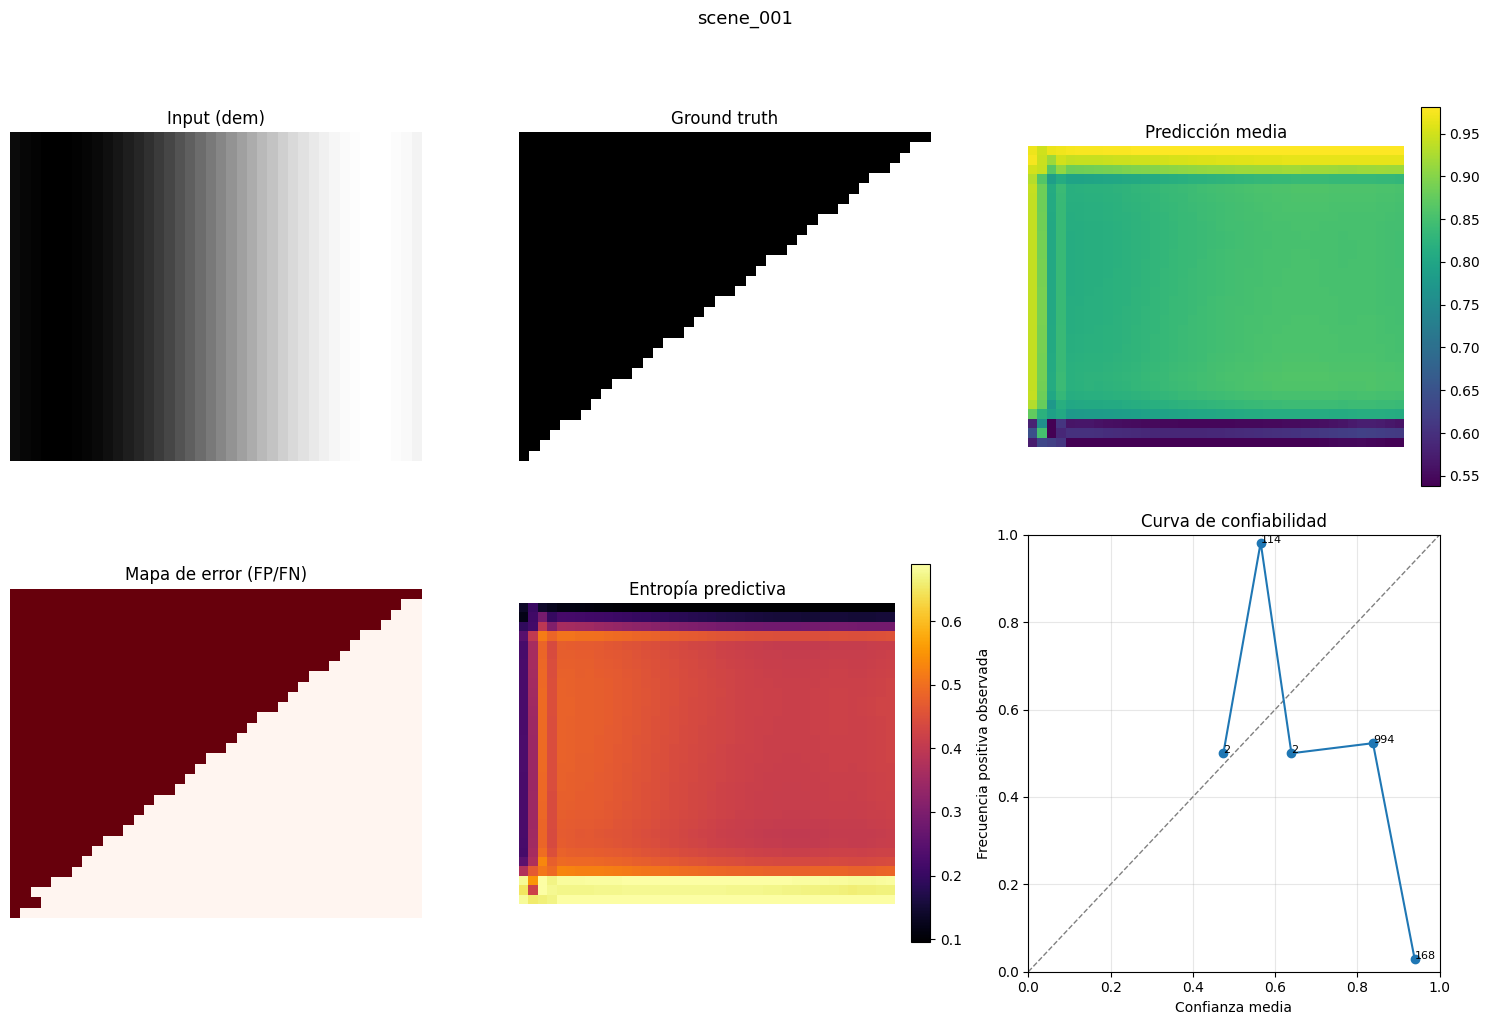

[scene_001]
  accuracy: 0.4992
  precision: 0.4992
  recall: 0.9984
  iou: 0.4988
  f1: 0.6656
  brier: 0.3955
  positive_fraction_gt: 0.4992
  positive_fraction_pred: 0.9984
  high_uncertainty_error_overlap: 0.0055
  entropy_mean: 0.4345
  mutual_information_mean: -0.0000


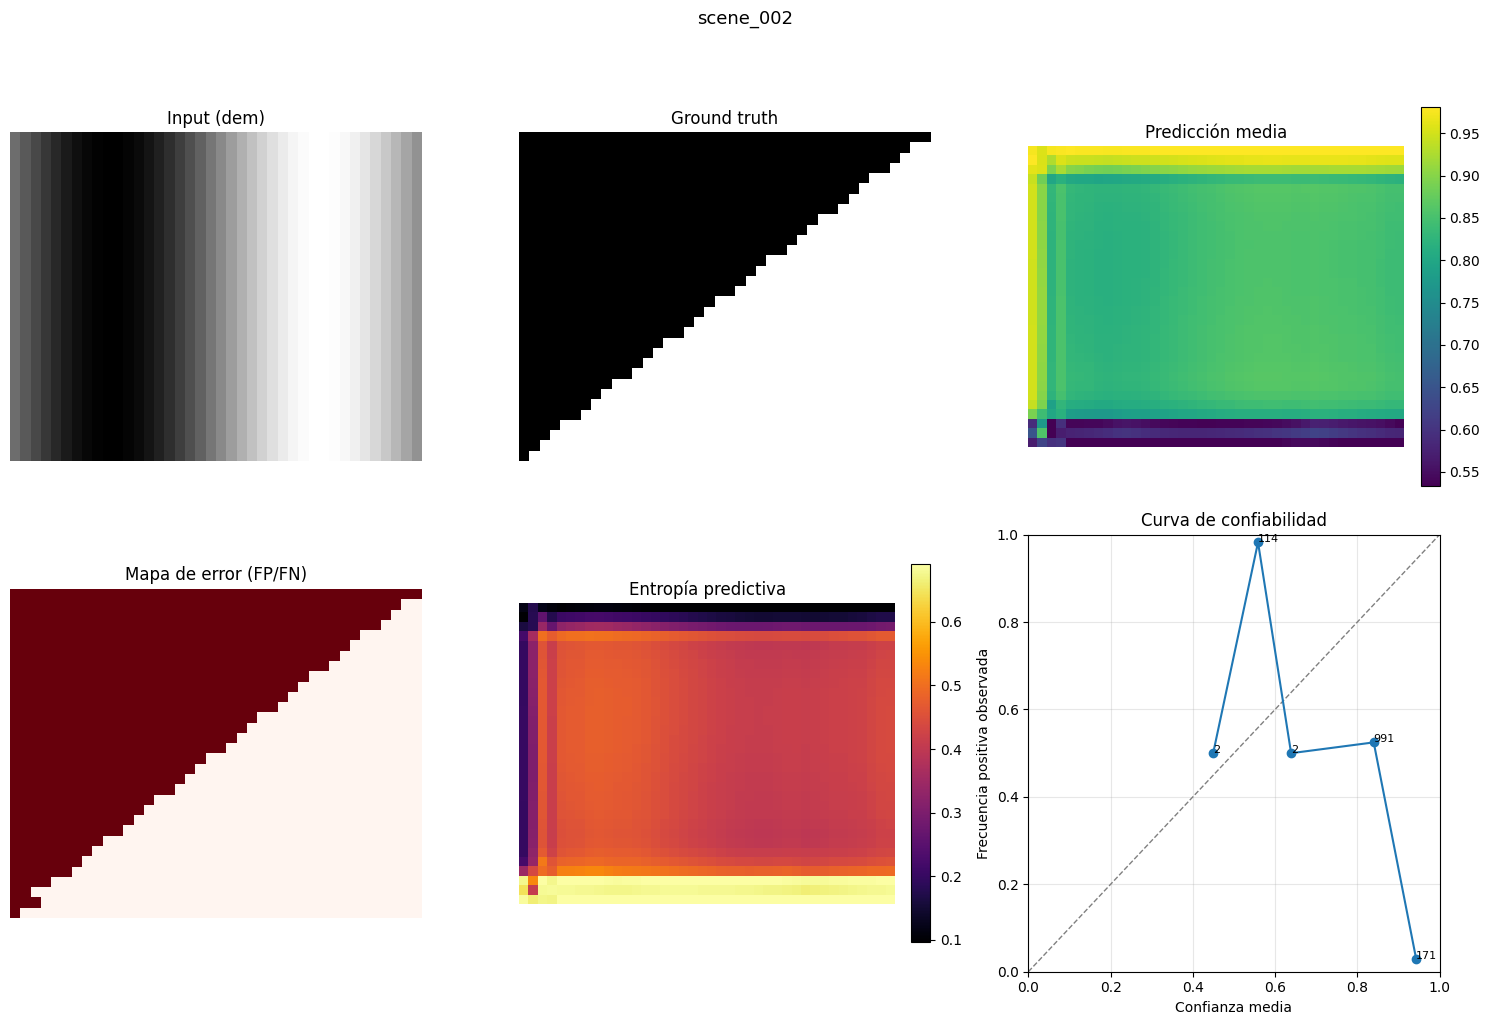

[scene_002]
  accuracy: 0.4992
  precision: 0.4992
  recall: 0.9984
  iou: 0.4988
  f1: 0.6656
  brier: 0.3995
  positive_fraction_gt: 0.4992
  positive_fraction_pred: 0.9984
  high_uncertainty_error_overlap: 0.0039
  entropy_mean: 0.4305
  mutual_information_mean: 0.0000


In [55]:
for sp, mp in zip(ms_stacks, ms_masks):
    scene_name = Path(sp).stem
    show_output_diagnostics(scene_name, sp, mp, UNCERT_DIR)

## 7. ¿Cómo se ven los lineamientos? Ground truth sobre los canales de entrada

Un **lineamento** es una estructura geológica lineal (falla, fractura, contacto litológico) que el modelo debe detectar. En la máscara binaria, un lineamento es un **trazo delgado de píxeles positivos** — normalmente < 1% del tile.

La célula siguiente selecciona los tiles con más lineamientos y los muestra de dos formas:
- **Overlay rojo** sobre el canal DEM: los píxeles positivos de la máscara pintados en rojo
- **Contorno amarillo** sobre todos los canales: el contorno del trazo de lineamento

Esto responde: *¿en qué parte de la señal geofísica aparece la firma del lineamento?*

Tiles Atrato seleccionados: 4
  stack_5bands_r04352_c00512.npy  pos=0.0065  nan=0.000
  stack_5bands_r07680_c01280.npy  pos=0.0060  nan=0.052
  stack_5bands_r04608_c00256.npy  pos=0.0056  nan=0.029
  stack_5bands_r05888_c02816.npy  pos=0.0053  nan=0.000


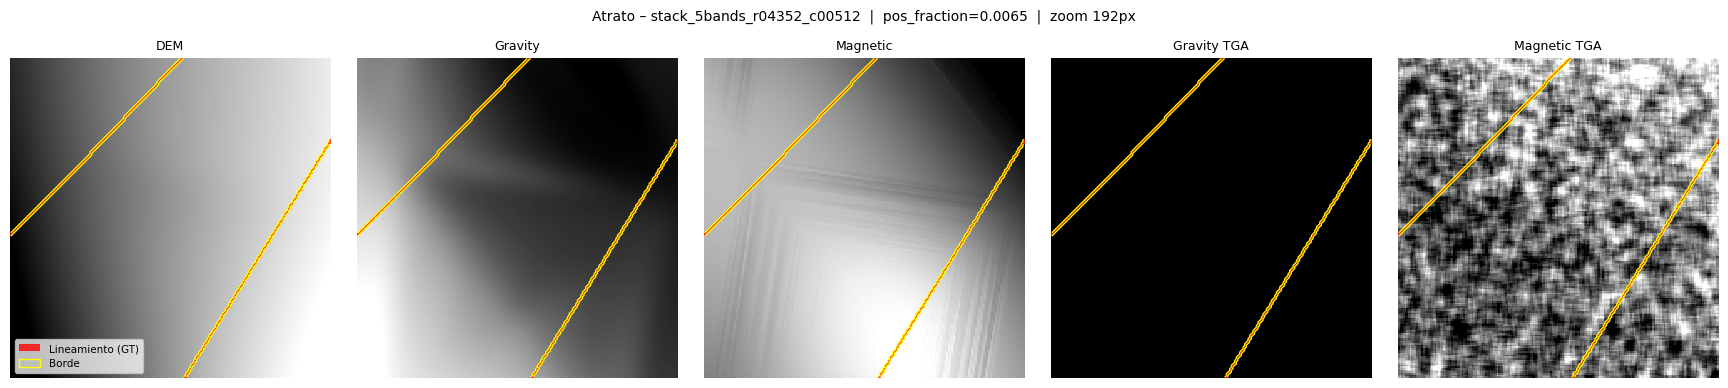

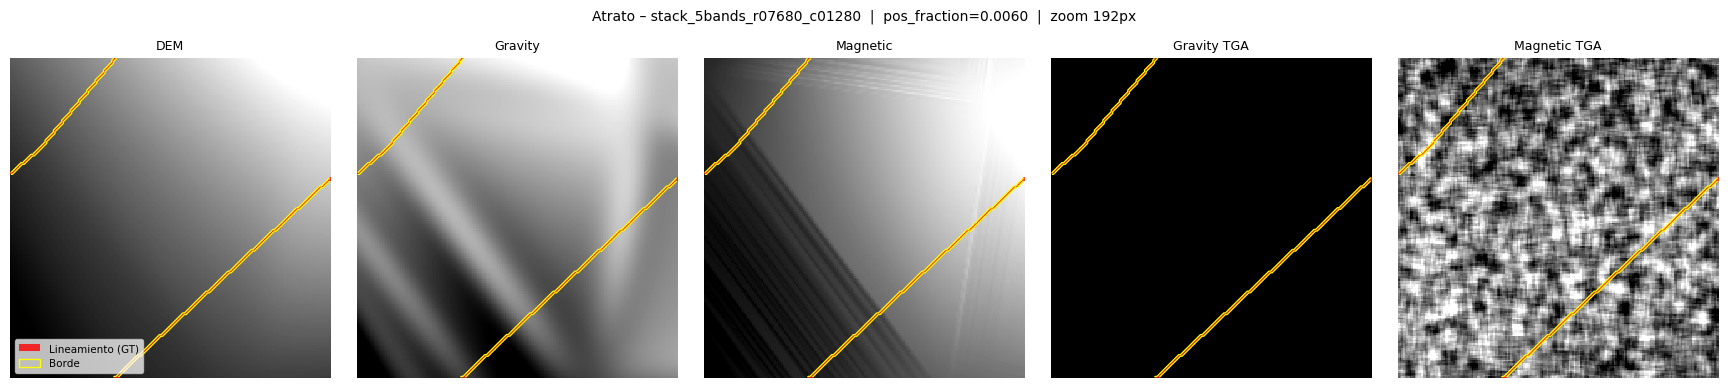

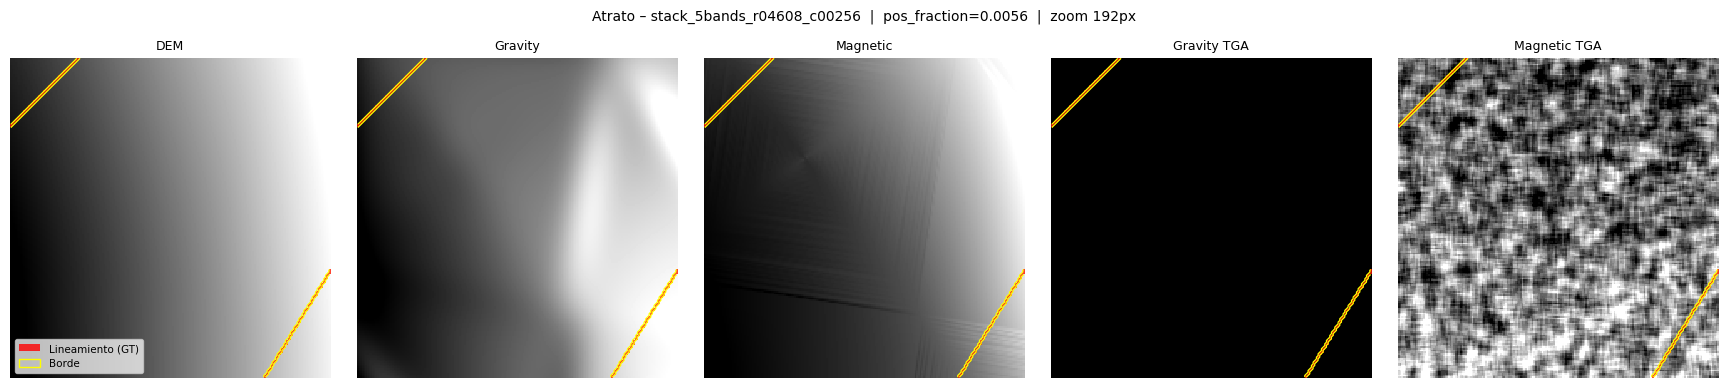

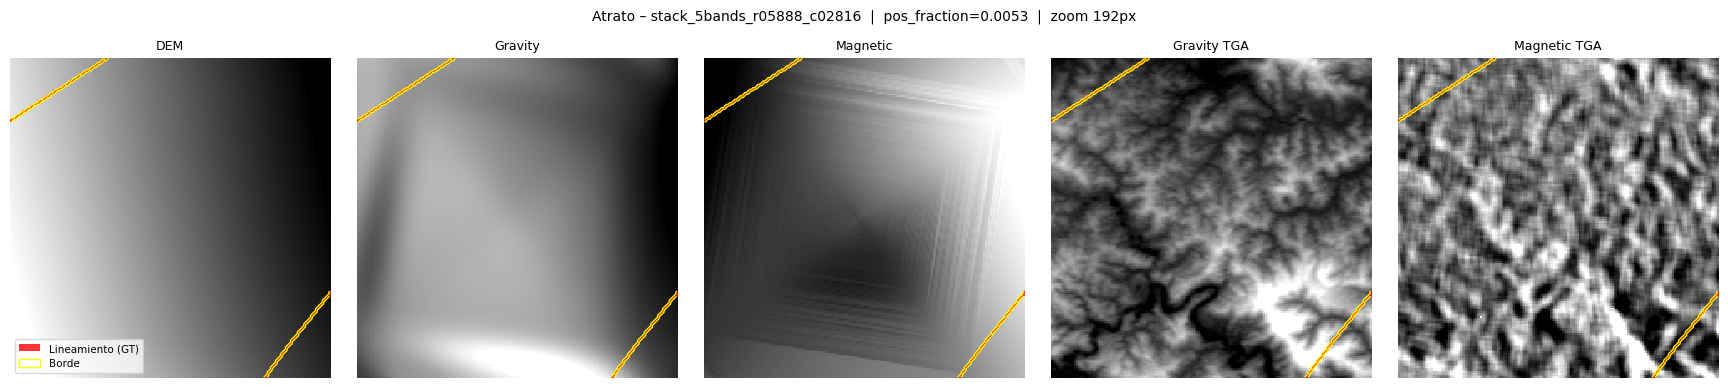

In [58]:
import json as _json
from matplotlib.patches import Patch

ATRATO_STACK_DIR = os.path.join(ROOT, 'data', 'atrato_training', 'stacks')
ATRATO_MASK_DIR  = os.path.join(ROOT, 'data', 'atrato_training', 'masks')
COL_STACK_DIR    = os.path.join(ROOT, 'data', 'Colombia', 'training', 'stacks')
COL_MASK_DIR     = os.path.join(ROOT, 'data', 'Colombia', 'training', 'masks')


def top_lineament_tiles(report_path, stack_dir, mask_dir, top_n=4):
    with open(report_path) as fh:
        rep = _json.load(fh)
    samples = rep['samples'] if isinstance(rep, dict) and 'samples' in rep else rep
    ranked = sorted(samples, key=lambda s: s['positive_fraction'], reverse=True)
    results = []
    for s in ranked:
        sp = os.path.join(stack_dir, s['sample'] + '.npy')
        mp = os.path.join(mask_dir,  s['sample'] + '.npy')
        if os.path.exists(sp) and os.path.exists(mp):
            results.append((sp, mp, s['positive_fraction'], s.get('nan_fraction', 0.0)))
        if len(results) >= top_n:
            break
    return results


def show_lineament_overlay(stack_path, mask_path, band_names, title='', zoom=True, zoom_size=192):
    """Muestra cada banda con los píxeles de lineamiento resaltados en rojo + contorno amarillo."""
    stack = np.load(stack_path)
    mask  = np.load(mask_path)
    n_bands = stack.shape[2]
    lineament_px = np.argwhere(mask > 0.5)

    if zoom and len(lineament_px) > 0:
        cy = int(np.median(lineament_px[:, 0]))
        cx = int(np.median(lineament_px[:, 1]))
        half = zoom_size // 2
        r0 = max(0, cy - half); r1 = min(stack.shape[0], r0 + zoom_size)
        c0 = max(0, cx - half); c1 = min(stack.shape[1], c0 + zoom_size)
        sv = stack[r0:r1, c0:c1, :]
        mv = mask[r0:r1, c0:c1]
    else:
        sv, mv = stack, mask

    # Overlay RGBA rojo semitransparente donde mask == 1
    overlay = np.zeros((*mv.shape, 4), dtype=np.float32)
    overlay[mv > 0.5] = [1.0, 0.1, 0.0, 0.80]

    fig, axes = plt.subplots(1, n_bands, figsize=(3.5 * n_bands, 3.8))
    if n_bands == 1:
        axes = [axes]
    for i, ax in enumerate(axes):
        band = sv[:, :, i]
        vlo  = np.nanpercentile(band, 2)
        vhi  = np.nanpercentile(band, 98)
        ax.imshow(band, cmap='gray', vmin=vlo, vmax=vhi, interpolation='nearest')
        ax.imshow(overlay, interpolation='nearest')
        ax.contour(mv, levels=[0.5], colors=['yellow'], linewidths=[0.9])
        ax.set_title(band_names[i] if i < len(band_names) else f'B{i}', fontsize=9)
        ax.axis('off')
    handles = [Patch(facecolor='red', alpha=0.80, label='Lineamiento (GT)'),
               Patch(edgecolor='yellow', facecolor='none', label='Borde')]
    axes[0].legend(handles=handles, loc='lower left', fontsize=7.5, framealpha=0.75)
    pos_f = float(np.mean(mask > 0.5))
    fig.suptitle(f'{title}  |  pos_fraction={pos_f:.4f}  |  zoom {zoom_size}px',
                 fontsize=10, y=1.01)
    plt.tight_layout()
    plt.show()


# ── Atrato: top-4 tiles con más lineamientos ───────────────────────────────
atrato_report = os.path.join(ROOT, 'data', 'atrato_training', 'report.json')
atrato_top    = top_lineament_tiles(atrato_report, ATRATO_STACK_DIR, ATRATO_MASK_DIR, top_n=4)
print(f'Tiles Atrato seleccionados: {len(atrato_top)}')
for sp, mp, pf, nf in atrato_top:
    print(f'  {os.path.basename(sp)}  pos={pf:.4f}  nan={nf:.3f}')

for sp, mp, pf, nf in atrato_top:
    tile_name = os.path.basename(sp).replace('.npy', '')
    show_lineament_overlay(sp, mp, BAND_NAMES, title=f'Atrato – {tile_name}')


Tiles Colombia seleccionados: 3
  stack_5bands_r10496_c05632.npy  pos=0.0116
  stack_5bands_r10240_c05632.npy  pos=0.0106
  stack_5bands_r10496_c05888.npy  pos=0.0103


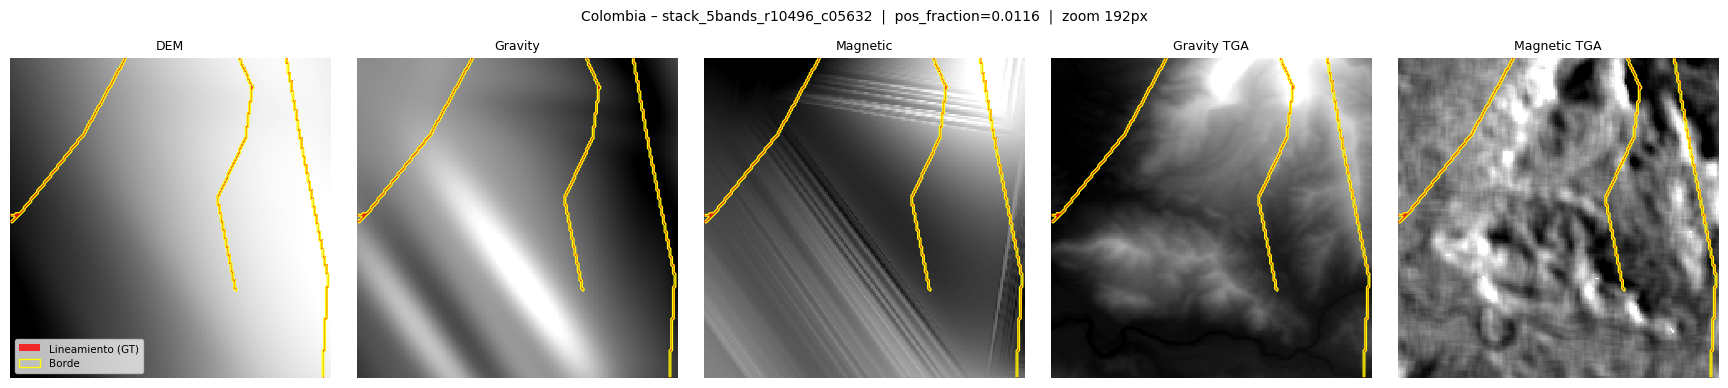

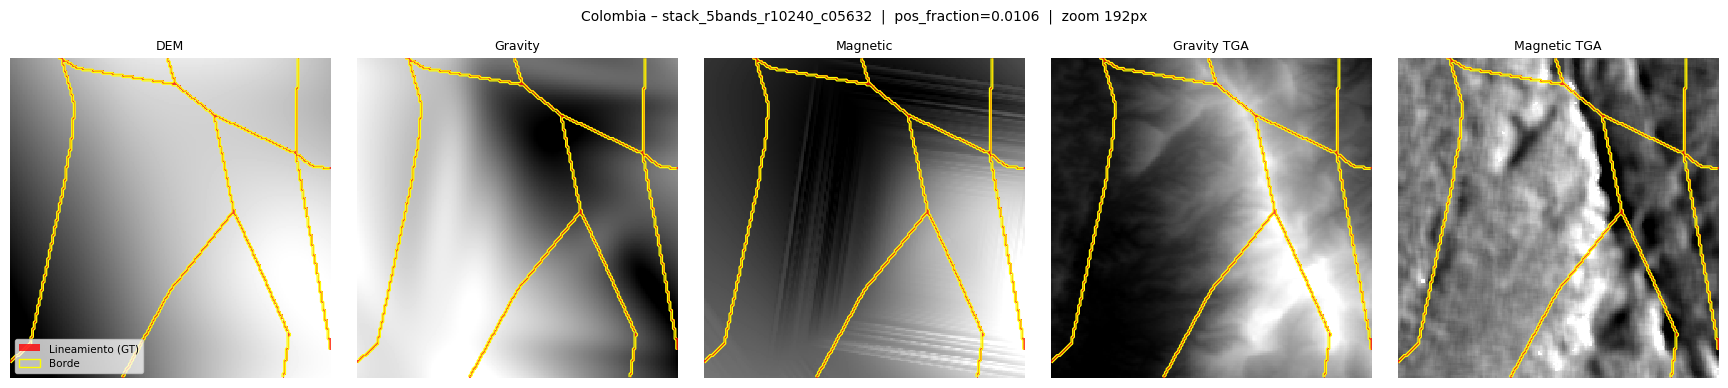

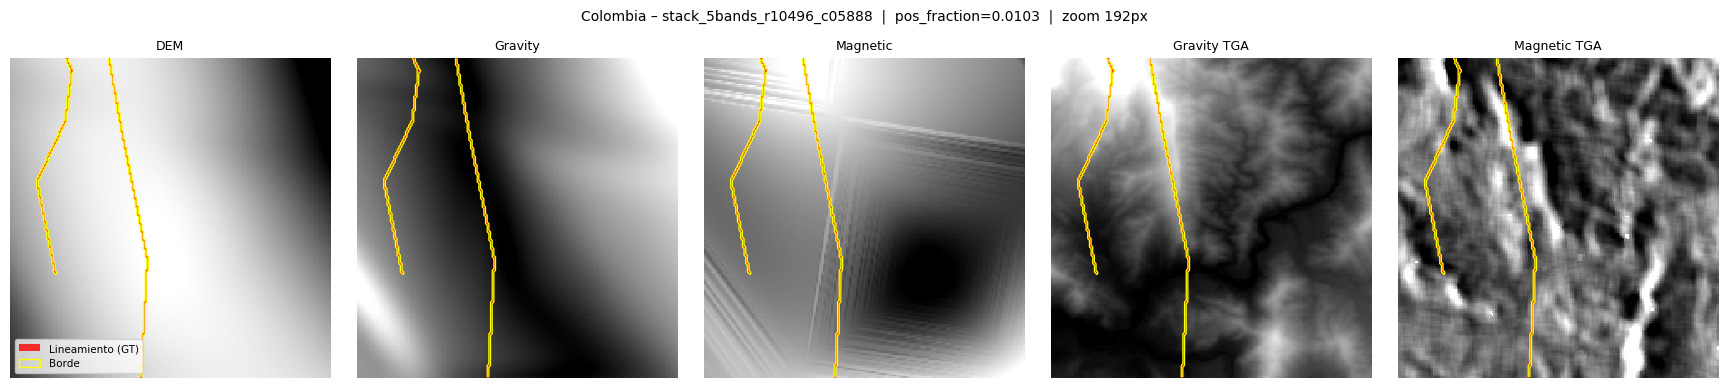


CALIFORNIA – San Andreas Fault: ¿qué busca el modelo?

Este modelo fue entrenado con 5 canales geofísicos:
  1. DEM          – topografía (en Colombia: Andes, valles fluviales)
  2. Gravedad Bouguer – contraste de densidad entre bloques de corteza
  3. Campo Magnético Total (TMI) – discontinuidades en formaciones ígneas
  4. Gradiente Total de Gravedad (TGA) – bordes de cuerpos densos
  5. Gradiente Total Magnético (TGA_m) – bordes de cuerpos magnéticos

En California (falla de San Andrés), el modelo detectaría:
  - DEM        : escarpe lineal NW-SE, corrientes desplazadas, sag ponds
  - Gravedad   : gradiente pronunciado en la transición Pacífico-continente
  - Magnético  : desplazamiento de formaciones volcánicas a lo largo del trazo
  - TGA grav/mag: máximos lineares coincidentes con la traza de la falla

NOTA: Los datos Sentinel-2 actuales (RGB/NIR óptico) NO son entrada válida
para este modelo.  Para inferir sobre California se necesitaría:
  • DEM → SRTM 30 m o NASADEM sobre Cal

In [59]:
# ── Colombia: top-3 tiles con mayor densidad de lineamientos ─────────────
col_report = os.path.join(ROOT, 'data', 'Colombia', 'training', 'tile_report.json')
col_top     = top_lineament_tiles(col_report, COL_STACK_DIR, COL_MASK_DIR, top_n=3)
print(f'Tiles Colombia seleccionados: {len(col_top)}')
for sp, mp, pf, nf in col_top:
    print(f'  {os.path.basename(sp)}  pos={pf:.4f}')

for sp, mp, pf, nf in col_top:
    tile_name = os.path.basename(sp).replace('.npy', '')
    show_lineament_overlay(sp, mp, BAND_NAMES, title=f'Colombia – {tile_name}')

# ── ¿Qué esperaría encontrar el modelo en California? ──────────────────────
print()
print('='*70)
print('CALIFORNIA – San Andreas Fault: ¿qué busca el modelo?')
print('='*70)
print('''
Este modelo fue entrenado con 5 canales geofísicos:
  1. DEM          – topografía (en Colombia: Andes, valles fluviales)
  2. Gravedad Bouguer – contraste de densidad entre bloques de corteza
  3. Campo Magnético Total (TMI) – discontinuidades en formaciones ígneas
  4. Gradiente Total de Gravedad (TGA) – bordes de cuerpos densos
  5. Gradiente Total Magnético (TGA_m) – bordes de cuerpos magnéticos

En California (falla de San Andrés), el modelo detectaría:
  - DEM        : escarpe lineal NW-SE, corrientes desplazadas, sag ponds
  - Gravedad   : gradiente pronunciado en la transición Pacífico-continente
  - Magnético  : desplazamiento de formaciones volcánicas a lo largo del trazo
  - TGA grav/mag: máximos lineares coincidentes con la traza de la falla

NOTA: Los datos Sentinel-2 actuales (RGB/NIR óptico) NO son entrada válida
para este modelo.  Para inferir sobre California se necesitaría:
  • DEM → SRTM 30 m o NASADEM sobre California
  • Anomalía de Bouguer → USGS/EarthScope gravity data
  • TMI → USGS aeromagnetic surveys
Los mismos preprocesos aplicados a Colombia (TGA, interpolación, normalización)
deberían aplicarse antes de apilar los 5 canales y ejecutar el modelo.
''')


In [ ]:
# 8. Evaluacion del ultimo modelo guardado sobre Colombia
import torch
from torch.utils.data import DataLoader
from src.model.Org_UNet import UNet
from src.preprocessing.multisource_dataset import MultiSourceStackDataset

CKPT_PATH = os.path.join(ROOT, 'data', 'atrato_training', 'checkpoints', 'atrato_unet.pt')
COL_STACK_DIR = os.path.join(ROOT, 'data', 'Colombia', 'training', 'stacks')
COL_MASK_DIR = os.path.join(ROOT, 'data', 'Colombia', 'training', 'masks')
OUT_STATS_JSON = os.path.join(ROOT, 'data', 'Colombia', 'training', 'atrato_unet_eval_on_colombia.json')

ckpt = torch.load(CKPT_PATH, map_location='cpu')
in_channels = int(ckpt.get('input_channels', 5))
model = UNet(n_classes=1, input_channels=in_channels)
model.load_state_dict(ckpt['model_state_dict'])
model.eval()

col_ds = MultiSourceStackDataset(COL_STACK_DIR, COL_MASK_DIR, normalize=True)
col_loader = DataLoader(col_ds, batch_size=4, shuffle=False, num_workers=0)

all_probs, all_gt = [], []
tile_stats = []

with torch.no_grad():
    i0 = 0
    for xb, yb in col_loader:
        probs = torch.sigmoid(model(xb))
        b = xb.shape[0]
        for i in range(b):
            p = probs[i, 0].cpu().numpy().astype(np.float32)
            g = (yb[i, 0].cpu().numpy() > 0.5).astype(np.uint8)
            pred05 = (p >= 0.5).astype(np.uint8)

            tp = int(((pred05 == 1) & (g == 1)).sum())
            tn = int(((pred05 == 0) & (g == 0)).sum())
            fp = int(((pred05 == 1) & (g == 0)).sum())
            fn = int(((pred05 == 0) & (g == 1)).sum())

            precision = tp / (tp + fp + 1e-9)
            recall = tp / (tp + fn + 1e-9)
            f1 = (2 * precision * recall) / (precision + recall + 1e-9)
            iou = tp / (tp + fp + fn + 1e-9)
            acc = (tp + tn) / (tp + tn + fp + fn + 1e-9)
            brier = float(np.mean((p - g.astype(np.float32)) ** 2))

            tile_stats.append({
                'tile': col_ds.stack_files[i0 + i],
                'positive_fraction_gt': float(g.mean()),
                'positive_fraction_pred_05': float(pred05.mean()),
                'tp': tp, 'tn': tn, 'fp': fp, 'fn': fn,
                'precision': float(precision), 'recall': float(recall),
                'f1': float(f1), 'iou': float(iou),
                'accuracy': float(acc), 'brier': brier,
            })

        i0 += b
        all_probs.append(probs.cpu().numpy().reshape(-1))
        all_gt.append((yb.cpu().numpy().reshape(-1) > 0.5).astype(np.uint8))

all_probs = np.concatenate(all_probs)
all_gt = np.concatenate(all_gt)
pred05 = (all_probs >= 0.5).astype(np.uint8)

tp = int(((pred05 == 1) & (all_gt == 1)).sum())
tn = int(((pred05 == 0) & (all_gt == 0)).sum())
fp = int(((pred05 == 1) & (all_gt == 0)).sum())
fn = int(((pred05 == 0) & (all_gt == 1)).sum())

precision05 = tp / (tp + fp + 1e-9)
recall05 = tp / (tp + fn + 1e-9)
f105 = (2 * precision05 * recall05) / (precision05 + recall05 + 1e-9)
iou05 = tp / (tp + fp + fn + 1e-9)
acc05 = (tp + tn) / (tp + tn + fp + fn + 1e-9)
brier = float(np.mean((all_probs - all_gt.astype(np.float32)) ** 2))

thresholds = np.linspace(0.05, 0.95, 19)
best = None
sweep = []
for t in thresholds:
    pred_t = (all_probs >= t).astype(np.uint8)
    tp_t = int(((pred_t == 1) & (all_gt == 1)).sum())
    tn_t = int(((pred_t == 0) & (all_gt == 0)).sum())
    fp_t = int(((pred_t == 1) & (all_gt == 0)).sum())
    fn_t = int(((pred_t == 0) & (all_gt == 1)).sum())

    prec_t = tp_t / (tp_t + fp_t + 1e-9)
    rec_t = tp_t / (tp_t + fn_t + 1e-9)
    f1_t = (2 * prec_t * rec_t) / (prec_t + rec_t + 1e-9)
    iou_t = tp_t / (tp_t + fp_t + fn_t + 1e-9)
    acc_t = (tp_t + tn_t) / (tp_t + tn_t + fp_t + fn_t + 1e-9)

    row = {
        'threshold': float(t),
        'tp': tp_t, 'tn': tn_t, 'fp': fp_t, 'fn': fn_t,
        'precision': float(prec_t), 'recall': float(rec_t),
        'f1': float(f1_t), 'iou': float(iou_t), 'accuracy': float(acc_t),
        'pred_positive_fraction': float(pred_t.mean()),
    }
    sweep.append(row)
    if best is None or row['f1'] > best['f1']:
        best = row

result = {
    'checkpoint': CKPT_PATH,
    'dataset': {
        'stack_dir': COL_STACK_DIR,
        'mask_dir': COL_MASK_DIR,
        'n_tiles': len(col_ds),
        'pixels_total': int(all_gt.size),
        'gt_positive_fraction': float(all_gt.mean()),
        'checkpoint_input_channels': in_channels,
    },
    'metrics_at_threshold_0_5': {
        'threshold': 0.5,
        'tp': tp, 'tn': tn, 'fp': fp, 'fn': fn,
        'precision': float(precision05), 'recall': float(recall05),
        'f1': float(f105), 'iou': float(iou05), 'accuracy': float(acc05),
        'brier': brier,
        'pred_positive_fraction': float(pred05.mean()),
    },
    'best_f1_threshold': best,
    'threshold_sweep': sweep,
    'tile_stats_summary': {
        'f1_mean': float(np.mean([t['f1'] for t in tile_stats])),
        'f1_std': float(np.std([t['f1'] for t in tile_stats])),
        'iou_mean': float(np.mean([t['iou'] for t in tile_stats])),
        'precision_mean': float(np.mean([t['precision'] for t in tile_stats])),
        'recall_mean': float(np.mean([t['recall'] for t in tile_stats])),
    },
    'top_5_tiles_by_f1': sorted(tile_stats, key=lambda x: x['f1'], reverse=True)[:5],
    'bottom_5_tiles_by_f1': sorted(tile_stats, key=lambda x: x['f1'])[:5],
}

with open(OUT_STATS_JSON, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, indent=2)

print('Evaluacion terminada')
print('Archivo:', OUT_STATS_JSON)
print('n_tiles:', result['dataset']['n_tiles'])
print('gt_positive_fraction:', f"{result['dataset']['gt_positive_fraction']:.6f}")
print('Metrics@0.5:', result['metrics_at_threshold_0_5'])
print('Best F1 threshold:', result['best_f1_threshold'])
print('Tile summary:', result['tile_stats_summary'])
